**<h3 style="color:orange">Please make sure any LLM coding assistant like Github Copilot or Cursus is turned OFF!</h2>**

**<h4 style="color:orange">We want you to learn and think critically, not to let LLMs do your work for you.</h4>**

**<h4 style="color:orange">Ask your group members or the internet for help, BEFORE asking your favorite chatbot.</h4>**

<img src="../figures/copilot.png">

# Assignment 1 Part 1: Learning Eulerian dynamics with neural networks

In this assignment, you will learn a discrete time-evolution operator for the two-dimensional Navier-Stokes equations. The state is represented in an **Eulerian** frame: vorticity is stored at fixed points on a spatial grid rather than by following fluid particles. Given a vorticity field $\omega_t(x,y)$, the prediction task is

$$\mathcal{G}_\theta:\omega_t \mapsto \widehat{\omega}_{t+1}.$$

You will study how architectural choices and training strategies affect one-step accuracy, autoregressive stability, and computational efficiency. The notebook uses trajectories from a two-dimensional Navier-Stokes benchmark and compares a periodic U-Net, a full spatial Transformer, and a Transolver-inspired physics-slice Transformer.

## What is provided

The data preparation, normalization, train/validation/test split, metrics, visualization functions, and rollout utilities are fully implemented. The following two baseline models and their complete training and evaluation pipelines are also provided:

- **Periodic U-Net:** a convolutional model with circular padding, multiple spatial resolutions, and skip connections.
- **Spatial Transformer:** a token-based model that applies full self-attention across all grid points.

Run these sections to train and evaluate both baselines. Their one-step results, rollout errors, and runtime provide the reference values for your implementations. You are not expected to reimplement these models.

## What you must implement

The assignment contains two implementation tasks:

1. **Physics-slice Transformer (Section 8).** Implement `PhysicsSliceAttention`, `PhysicsSliceBlock`, and `PhysicsSliceTransformer`. The mathematical construction, tensor shapes, class interfaces, and surrounding training and evaluation code are provided. You must complete the three model classes, train the model, and compare its accuracy and speed with the supplied baselines.

2. **Pushforward training (Section 10).** Design and implement pushforward training for a new physics-slice Transformer. This is an open-ended task: you must implement the required dataset, one-epoch training procedure, pushforward-step scheduler, validation and checkpointing logic, and any other necessary training code. Evaluate both one-step prediction and autoregressive rollout, then compare the result with the ordinarily trained physics-slice Transformer from Section 8.

## Working and submission expectations

Run the notebook in order because later sections reuse models, variables, and evaluation results from earlier sections. A GPU is strongly recommended for training. Keep the supplied dataset split, model-size hyperparameters, and evaluation definitions unchanged so that comparisons remain meaningful.

## 1. Setup and data

We begin by importing the required libraries, fixing random seeds, and selecting a GPU when one is available.

In [ ]:
from pathlib import Path
import random

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import copy
import time

from huggingface_hub import hf_hub_download

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


### Downloading and inspecting the dataset

The dataset is downloaded from the standard PDE benchmark collection and stored locally. We inspect its variables, dimensions, and an example transition before constructing training samples.

> The seed controls the main random-number generators, but exact reproducibility can still depend on hardware and low-level CUDA operations.

In [ ]:
DATA_DIR = Path("data/navier_stokes")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="kmario23/standard-pde-benchmark",
    repo_type="dataset",
    filename="ns/NavierStokes_V1e-5_N1200_T20.mat",
    local_dir=DATA_DIR,
)

data_path = Path(data_path)

print("Dataset path:")
print(data_path)

print(f"\nFile size: {data_path.stat().st_size / 1024**2:.1f} MB")

ns/NavierStokes_V1e-5_N1200_T20.mat: reconstructing file:   0%|          |  0.00B /  413MB            

ns/NavierStokes_V1e-5_N1200_T20.mat: downloading bytes:           |  0.00B            

Dataset path:
/content/data/navier_stokes/ns/NavierStokes_V1e-5_N1200_T20.mat

File size: 393.8 MB


In [ ]:
data = sio.loadmat(data_path)

print("Variables stored in the .mat file:")
print(data.keys())

Variables stored in the .mat file:
dict_keys(['__header__', '__version__', '__globals__', 'a', 'u', 't'])


In [ ]:
initial_vorticity = data["a"]   # omega(x, y, 0)
vorticity = data["u"]           # omega(x, y, t_1), ..., omega(x, y, t_20)

print("Initial conditions:", initial_vorticity.shape)
print("Trajectories:      ", vorticity.shape)
print("dtype:             ", vorticity.dtype)

Initial conditions: (1200, 64, 64)
Trajectories:       (1200, 64, 64, 20)
dtype:              float32


In [ ]:
n_trajectories, nx, ny, n_timesteps = vorticity.shape

print("Number of trajectories :", n_trajectories)
print("Spatial resolution     :", nx, "x", ny)
print("Number of time steps   :", n_timesteps)

Number of trajectories : 1200
Spatial resolution     : 64 x 64
Number of time steps   : 20


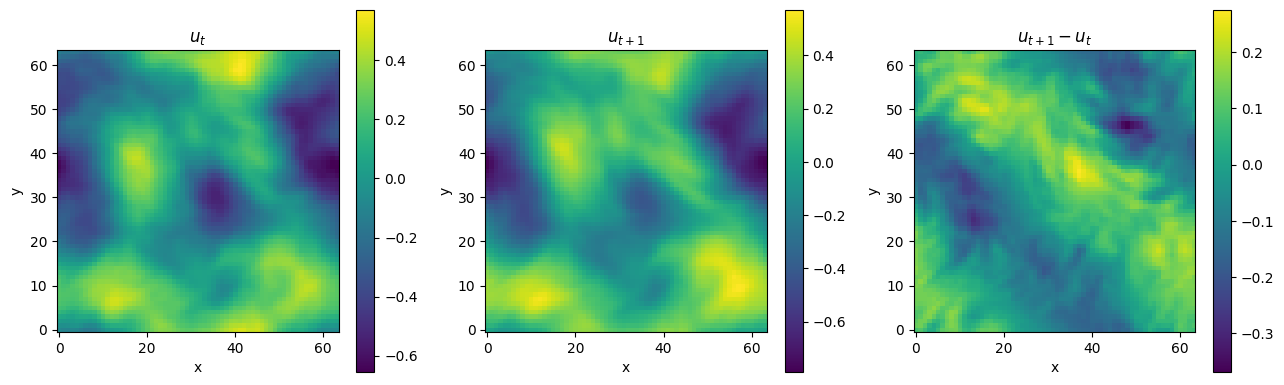

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

im0 = axes[0].imshow(vorticity[0,:,:,0], origin="lower")
axes[0].set_title(r"$u_t$")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(vorticity[0,:,:,1], origin="lower")
axes[1].set_title(r"$u_{t+1}$")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
plt.colorbar(im1, ax=axes[1])

difference = vorticity[0,:,:,1] - vorticity[0,:,:,0]
im2 = axes[2].imshow(difference, origin="lower")
axes[2].set_title(r"$u_{t+1} - u_t$")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## 2. From trajectories to supervised examples

Each simulation contains an initial condition $\omega_0$ and 20 later states $\omega_1,\ldots,\omega_{20}$. We convert every trajectory into 20 adjacent pairs

$$ (\omega_0,\omega_1), (\omega_1,\omega_2),\ldots,(\omega_{19},\omega_{20}). $$

The split is performed by **trajectory**, not by individual pairs. This prevents states from the same simulation appearing in both training and evaluation data. We also subsample the grid from $64\times64$ to $32\times32$ and compute normalization statistics using training data only.

In [ ]:
N_TRAIN = 900
N_VAL = 100
N_TEST = 200

train_indices = np.arange(0, 900)
val_indices = np.arange(900, 1000)
test_indices = np.arange(1000, 1200)

print("Train trajectories:", len(train_indices))
print("Val trajectories:  ", len(val_indices))
print("Test trajectories: ", len(test_indices))

Train trajectories: 900
Val trajectories:   100
Test trajectories:  200


In [ ]:
SPATIAL_STRIDE = 2

train_a = initial_vorticity[:N_TRAIN, ::SPATIAL_STRIDE, ::SPATIAL_STRIDE]

train_u = vorticity[
    :N_TRAIN,
    ::SPATIAL_STRIDE,
    ::SPATIAL_STRIDE,
    :
]

n_values = train_a.size + train_u.size

sum_values = (
    train_a.astype(np.float64).sum()
    + train_u.astype(np.float64).sum()
)

sum_squared = (
    np.square(train_a.astype(np.float64)).sum()
    + np.square(train_u.astype(np.float64)).sum()
)

omega_mean = sum_values / n_values
omega_var = sum_squared / n_values - omega_mean**2
omega_std = np.sqrt(omega_var)

print(f"Training mean: {omega_mean:.6f}")
print(f"Training std:  {omega_std:.6f}")

Training mean: 0.000019
Training std:  1.105457


In [ ]:
# Always reuse training-set statistics for validation and test data.
# Computing new statistics on those splits would leak information.
def normalize(x):
    return (x - omega_mean) / omega_std


def denormalize(x):
    return x * omega_std + omega_mean

### Dataset and data loaders

The custom PyTorch dataset maps a single integer index to a trajectory and time step. For the first transition the input comes from `a`; later inputs come from the preceding slice of `u`.

A channel dimension is added because PyTorch convolutional layers expect tensors ordered as `[batch, channels, height, width]`.

In [ ]:
class NavierStokesOneStepDataset(Dataset):
    """
    Dataset of one-step vorticity transitions:

        omega_t -> omega_{t+1}

    Each trajectory contains:
        omega_0 = initial_vorticity
        omega_1, ..., omega_20 = vorticity[..., 0:20]

    Therefore each trajectory gives 20 transitions.
    """

    def __init__(
        self,
        initial_vorticity,
        vorticity,
        trajectory_indices,
        mean,
        std,
        spatial_stride=1,
    ):
        self.initial_vorticity = initial_vorticity
        self.vorticity = vorticity
        self.trajectory_indices = np.asarray(trajectory_indices)

        self.mean = mean
        self.std = std
        self.spatial_stride = spatial_stride

        self.n_transitions = vorticity.shape[-1]  # 20


    def __len__(self):
        return len(self.trajectory_indices) * self.n_transitions


    def __getitem__(self, idx):

        # Which trajectory?
        trajectory_position = idx // self.n_transitions

        # Which transition inside that trajectory?
        t = idx % self.n_transitions

        trajectory_idx = self.trajectory_indices[trajectory_position]

        # -------------------------------------------------
        # Construct omega_t
        # -------------------------------------------------

        if t == 0:
            # omega_0 comes from "a"
            x = self.initial_vorticity[
                trajectory_idx,
                ::self.spatial_stride,
                ::self.spatial_stride,
            ]

        else:
            # omega_t is stored at u[..., t-1]
            x = self.vorticity[
                trajectory_idx,
                ::self.spatial_stride,
                ::self.spatial_stride,
                t - 1,
            ]

        # -------------------------------------------------
        # omega_{t+1}
        # -------------------------------------------------

        y = self.vorticity[
            trajectory_idx,
            ::self.spatial_stride,
            ::self.spatial_stride,
            t,
        ]

        # Convert to float32
        x = x.astype(np.float32)
        y = y.astype(np.float32)

        # Normalize
        x = (x - self.mean) / self.std
        y = (y - self.mean) / self.std

        # Convert to tensors
        x = torch.from_numpy(x)
        y = torch.from_numpy(y)

        # Add channel dimension:
        #
        # [H, W] -> [1, H, W]
        #
        x = x.unsqueeze(0)
        y = y.unsqueeze(0)

        return x, y

In [ ]:
train_dataset = NavierStokesOneStepDataset(
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    trajectory_indices=train_indices,
    mean=omega_mean,
    std=omega_std,
    spatial_stride=SPATIAL_STRIDE,
)

val_dataset = NavierStokesOneStepDataset(
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    trajectory_indices=val_indices,
    mean=omega_mean,
    std=omega_std,
    spatial_stride=SPATIAL_STRIDE,
)

test_dataset = NavierStokesOneStepDataset(
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    trajectory_indices=test_indices,
    mean=omega_mean,
    std=omega_std,
    spatial_stride=SPATIAL_STRIDE,
)

In [ ]:
print("Training samples:  ", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:      ", len(test_dataset))

Training samples:   18000
Validation samples: 2000
Test samples:       4000


In [ ]:
x, y = train_dataset[0]

print("Input shape: ", x.shape)
print("Target shape:", y.shape)
print("Input dtype: ", x.dtype)

Input shape:  torch.Size([1, 32, 32])
Target shape: torch.Size([1, 32, 32])
Input dtype:  torch.float64


In [ ]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

In [ ]:
x_batch, y_batch = next(iter(train_loader))

print("Input batch: ", x_batch.shape)
print("Target batch:", y_batch.shape)

Input batch:  torch.Size([128, 1, 32, 32])
Target batch: torch.Size([128, 1, 32, 32])


In [ ]:
# Keep one value per field so aggregation across samples remains explicit.
def mse_per_sample(pred, target):
    """
    pred, target: [B, C, H, W]

    Returns MSE for each sample:
    shape [B]
    """
    return (
        (pred - target)
        .pow(2)
        .flatten(1)
        .mean(dim=1)
    )


def relative_l2_error(pred, target, eps=1e-8):
    """
    Relative L2 error for each sample.

        ||pred - target||_2
        -------------------
            ||target||_2
    """

    diff_norm = torch.linalg.vector_norm(
        (pred - target).flatten(1),
        dim=1,
    )

    target_norm = torch.linalg.vector_norm(
        target.flatten(1),
        dim=1,
    )

    return diff_norm / (target_norm + eps)

## 3. A periodic U-Net

A U-Net combines local convolutions with information at several spatial scales. The encoder reduces resolution, the bottleneck processes coarse features, and the decoder reconstructs a full-resolution field using skip connections.

The physical domain is periodic. Circular padding wraps values from one side of the grid to the other instead of introducing artificial zeros at the boundary.

The network predicts a residual:

$$\widehat{\omega}_{t+1}=\omega_t+\Delta\omega_\theta(\omega_t).$$

This is a useful inductive bias when consecutive states are similar.

In [ ]:
class PeriodicConv2d(nn.Module):
    """
    2D convolution with periodic (circular) boundary conditions.
    """

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        bias=True,
    ):
        super().__init__()

        self.padding = kernel_size // 2

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            padding=0,
            bias=bias,
        )

    def forward(self, x):

        # Periodic padding:
        # left, right, top, bottom
        x = F.pad(
            x,
            (
                self.padding,
                self.padding,
                self.padding,
                self.padding,
            ),
            mode="circular",
        )

        return self.conv(x)

In [ ]:
class DoubleConv(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.block = nn.Sequential(

            PeriodicConv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                bias=False,
            ),

            nn.GroupNorm(
                num_groups=7,
                num_channels=out_channels,
            ),

            nn.GELU(),

            PeriodicConv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                bias=False,
            ),

            nn.GroupNorm(
                num_groups=7,
                num_channels=out_channels,
            ),

            nn.GELU(),
        )

    def forward(self, x):
        return self.block(x)

In [ ]:
class Down(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.conv = DoubleConv(
            in_channels,
            out_channels,
        )

    def forward(self, x):

        x = self.pool(x)
        x = self.conv(x)

        return x

In [ ]:
class Up(nn.Module):
    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
    ):
        super().__init__()

        self.conv = DoubleConv(
            in_channels + skip_channels,
            out_channels,
        )

    def forward(self, x, skip):

        # Upsample to the same resolution
        # as the corresponding encoder feature.
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

        # Skip connection
        x = torch.cat(
            [skip, x],
            dim=1,
        )

        x = self.conv(x)

        return x

In [ ]:
class UNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=1,
        base_channels=7,
    ):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8

        # -------------------------
        # Encoder
        # -------------------------

        self.enc1 = DoubleConv(
            in_channels,
            c1,
        )

        self.enc2 = Down(
            c1,
            c2,
        )

        self.enc3 = Down(
            c2,
            c3,
        )

        # -------------------------
        # Bottleneck
        # -------------------------

        self.bottleneck = Down(
            c3,
            c4,
        )

        # -------------------------
        # Decoder
        # -------------------------

        self.dec3 = Up(
            in_channels=c4,
            skip_channels=c3,
            out_channels=c3,
        )

        self.dec2 = Up(
            in_channels=c3,
            skip_channels=c2,
            out_channels=c2,
        )

        self.dec1 = Up(
            in_channels=c2,
            skip_channels=c1,
            out_channels=c1,
        )

        # -------------------------
        # Output
        # -------------------------

        self.output = nn.Conv2d(
            c1,
            out_channels,
            kernel_size=1,
        )


    def forward(self, x):

        input_state = x
        # Encoder
        x1 = self.enc1(x)       # [B, 32, H,   W]
        x2 = self.enc2(x1)      # [B, 64, H/2, W/2]
        x3 = self.enc3(x2)      # [B,128, H/4, W/4]

        # Bottleneck
        x4 = self.bottleneck(x3) # [B,256,H/8,W/8]

        # Decoder
        x = self.dec3(x4, x3)
        x = self.dec2(x,  x2)
        x = self.dec1(x,  x1)

        # Predict next vorticity field
        delta = self.output(x)

        return input_state + delta

In [ ]:
unet = UNet(
    in_channels=1,
    out_channels=1,
    base_channels=7,
).to(device)

print(unet)

UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): PeriodicConv2d(
        (conv): Conv2d(1, 7, kernel_size=(3, 3), stride=(1, 1), bias=False)
      )
      (1): GroupNorm(7, 7, eps=1e-05, affine=True)
      (2): GELU(approximate='none')
      (3): PeriodicConv2d(
        (conv): Conv2d(7, 7, kernel_size=(3, 3), stride=(1, 1), bias=False)
      )
      (4): GroupNorm(7, 7, eps=1e-05, affine=True)
      (5): GELU(approximate='none')
    )
  )
  (enc2): Down(
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv): DoubleConv(
      (block): Sequential(
        (0): PeriodicConv2d(
          (conv): Conv2d(7, 14, kernel_size=(3, 3), stride=(1, 1), bias=False)
        )
        (1): GroupNorm(7, 14, eps=1e-05, affine=True)
        (2): GELU(approximate='none')
        (3): PeriodicConv2d(
          (conv): Conv2d(14, 14, kernel_size=(3, 3), stride=(1, 1), bias=False)
        )
        (4): GroupNorm(7, 14, eps=1e-05, affine=True)
    

In [ ]:
n_params = sum(
    p.numel()
    for p in unet.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {n_params:,}")

Trainable parameters: 93,738


## 4. Training the U-Net

The model minimizes mean squared error in normalized coordinates. AdamW performs the updates, while cosine annealing gradually lowers the learning rate. The parameters with the lowest validation loss are retained rather than simply using the final epoch.

In [ ]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
N_EPOCHS = 30

criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    unet.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=N_EPOCHS,
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
):
    model.train()

    total_loss = 0.0
    n_samples = 0

    # Each batch contains independent one-step pairs: omega_t -> omega_{t+1}.
    for x, y in loader:

        x = x.to(device).float()
        y = y.to(device).float()

        # -------------------------
        # Forward
        # -------------------------
        pred = model(x)

        loss = criterion(pred, y)

        # -------------------------
        # Backpropagation
        # -------------------------
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        # -------------------------
        # Statistics
        # -------------------------
        batch_size = x.shape[0]

        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples

In [ ]:
@torch.no_grad()
def evaluate_loss(
    model,
    loader,
    criterion,
    device,
):
    model.eval()

    total_loss = 0.0
    n_samples = 0

    for x, y in loader:

        x = x.to(device).float()
        y = y.to(device).float()

        pred = model(x)

        loss = criterion(pred, y)

        batch_size = x.shape[0]

        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples

In [ ]:
train_losses = []
val_losses = []
learning_rates = []

best_val_loss = float("inf")
best_model_state = None

start_time = time.time()

for epoch in range(1, N_EPOCHS + 1):

    # -------------------------
    # Train
    # -------------------------
    train_loss = train_one_epoch(
        model=unet,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device,
    )

    # -------------------------
    # Validation
    # -------------------------
    val_loss = evaluate_loss(
        model=unet,
        loader=val_loader,
        criterion=criterion,
        device=device,
    )

    # Record history
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    learning_rates.append(
        optimizer.param_groups[0]["lr"]
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            unet.state_dict()
        )

    # Update learning rate
    scheduler.step()

    print(
        f"Epoch {epoch:3d}/{N_EPOCHS} | "
        f"Train loss: {train_loss:.6e} | "
        f"Val loss: {val_loss:.6e} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )


elapsed = time.time() - start_time

print()
print(
    f"Training finished in "
    f"{elapsed / 60:.1f} minutes"
)

print(
    f"Best validation loss: "
    f"{best_val_loss:.6e}"
)

Epoch   1/30 | Train loss: 9.366028e-02 | Val loss: 5.657026e-02 | LR: 9.97e-04
Epoch   2/30 | Train loss: 4.826407e-02 | Val loss: 4.246344e-02 | LR: 9.89e-04
Epoch   3/30 | Train loss: 3.950748e-02 | Val loss: 3.716122e-02 | LR: 9.76e-04
Epoch   4/30 | Train loss: 3.493618e-02 | Val loss: 3.276555e-02 | LR: 9.57e-04
Epoch   5/30 | Train loss: 3.157882e-02 | Val loss: 3.111225e-02 | LR: 9.33e-04
Epoch   6/30 | Train loss: 2.997586e-02 | Val loss: 2.986992e-02 | LR: 9.05e-04
Epoch   7/30 | Train loss: 2.837446e-02 | Val loss: 2.778640e-02 | LR: 8.72e-04
Epoch   8/30 | Train loss: 2.699883e-02 | Val loss: 2.658773e-02 | LR: 8.35e-04
Epoch   9/30 | Train loss: 2.622319e-02 | Val loss: 2.571709e-02 | LR: 7.94e-04
Epoch  10/30 | Train loss: 2.517178e-02 | Val loss: 2.548901e-02 | LR: 7.50e-04
Epoch  11/30 | Train loss: 2.431598e-02 | Val loss: 2.565204e-02 | LR: 7.03e-04
Epoch  12/30 | Train loss: 2.373423e-02 | Val loss: 2.497812e-02 | LR: 6.55e-04
Epoch  13/30 | Train loss: 2.307118e-02 

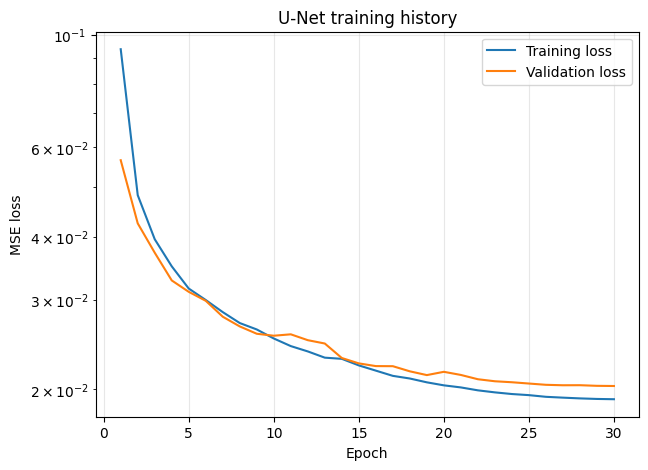

In [ ]:
epochs = np.arange(
    1,
    len(train_losses) + 1,
)

plt.figure(figsize=(7, 5))

plt.plot(
    epochs,
    train_losses,
    label="Training loss",
)

plt.plot(
    epochs,
    val_losses,
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("U-Net training history")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [ ]:
unet.load_state_dict(best_model_state)

unet.eval()

print("Best U-Net restored.")

Best U-Net restored.


## 5. One-step evaluation

We first evaluate individual transitions from unseen trajectories. Predictions and targets are converted back to physical units before computing:

- **MSE**, the average squared error per grid point;
- **relative $L^2$ error**, $\lVert\widehat{\omega}-\omega\rVert_2/\lVert\omega\rVert_2$, the error relative to the target magnitude.

Spatial plots can reveal structured errors that a single scalar metric hides.

In [ ]:
@torch.no_grad()
def evaluate_one_step(
    model,
    loader,
    mean,
    std,
    device,
):
    model.eval()

    mse_values = []
    rel_l2_values = []

    for x, y in loader:

        x = x.to(device).float()
        y = y.to(device).float()

        # Prediction in normalized space
        pred = model(x)

        # Convert back to physical scale
        pred_phys = pred * std + mean
        y_phys = y * std + mean

        # MSE per sample
        mse = (
            (pred_phys - y_phys)
            .pow(2)
            .flatten(1)
            .mean(dim=1)
        )

        # Relative L2 per sample
        diff_norm = torch.linalg.vector_norm(
            (pred_phys - y_phys).flatten(1),
            dim=1,
        )

        target_norm = torch.linalg.vector_norm(
            y_phys.flatten(1),
            dim=1,
        )

        rel_l2 = diff_norm / (
            target_norm + 1e-8
        )

        mse_values.append(
            mse.cpu()
        )

        rel_l2_values.append(
            rel_l2.cpu()
        )

    mse_values = torch.cat(mse_values)
    rel_l2_values = torch.cat(
        rel_l2_values
    )

    return {
        "MSE": mse_values.mean().item(),
        "Relative L2": (
            rel_l2_values.mean().item()
        ),
    }

In [ ]:
unet_test_results = evaluate_one_step(
    model=unet,
    loader=test_loader,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

print("U-Net one-step test results")
print("---------------------------")

for metric, value in unet_test_results.items():
    print(
        f"{metric:12s}: {value:.6e}"
    )

U-Net one-step test results
---------------------------
MSE         : 2.643542e-02
Relative L2 : 1.354689e-01


In [ ]:
@torch.no_grad()
def plot_one_step_prediction(
    model,
    dataset,
    sample_idx,
    mean,
    std,
    device,
):

    model.eval()

    x, y = dataset[sample_idx]

    x_batch = (
        x.unsqueeze(0)
        .to(device).float()
    )

    pred = model(x_batch)[0].cpu()

    # Convert to physical units
    x_phys = (
        x * std + mean
    ).squeeze().numpy()

    y_phys = (
        y * std + mean
    ).squeeze().numpy()

    pred_phys = (
        pred * std + mean
    ).squeeze().numpy()

    error = np.abs(
        pred_phys - y_phys
    )

    vmin = min(
        x_phys.min(),
        y_phys.min(),
        pred_phys.min(),
    )

    vmax = max(
        x_phys.max(),
        y_phys.max(),
        pred_phys.max(),
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(16, 4),
    )

    im = axes[0].imshow(
        x_phys,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    axes[0].set_title(
        r"Input $\omega_t$"
    )

    axes[1].imshow(
        y_phys,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    axes[1].set_title(
        r"True $\omega_{t+1}$"
    )

    axes[2].imshow(
        pred_phys,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    axes[2].set_title(
        r"Predicted $\hat{\omega}_{t+1}$"
    )

    err_im = axes[3].imshow(
        error,
        origin="lower",
    )

    axes[3].set_title(
        "Absolute error"
    )

    plt.colorbar(
        im,
        ax=axes[:3],
        shrink=0.8,
    )

    plt.colorbar(
        err_im,
        ax=axes[3],
        shrink=0.8,
    )

    plt.show()

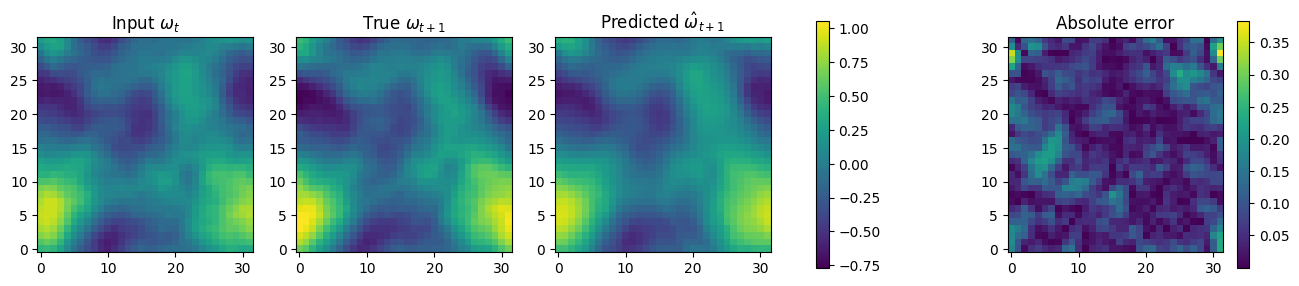

In [ ]:
plot_one_step_prediction(
    model=unet,
    dataset=test_dataset,
    sample_idx=100,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

## 6. Multi-step prediction

One-step accuracy does not fully describe a dynamical surrogate. We compare two multi-step modes:

- **Teacher forcing:** every prediction receives the true current state, isolating one-step approximation error.
- **Autoregressive rollout:** every prediction becomes the next input, testing stability and accumulated distribution shift.

A model can perform well under teacher forcing yet drift autoregressively because it was trained on true states but encounters its own imperfect predictions at inference time.

In [ ]:
def get_trajectory(
    trajectory_idx,
    initial_vorticity,
    vorticity,
    spatial_stride=1,
):
    """
    Returns a complete trajectory

        omega_0, ..., omega_20

    Shape:
        [21, H, W]
    """

    omega0 = initial_vorticity[
        trajectory_idx,
        ::spatial_stride,
        ::spatial_stride,
    ]

    future = vorticity[
        trajectory_idx,
        ::spatial_stride,
        ::spatial_stride,
        :,
    ]

    # future currently:
    # [H, W, 20]
    #
    # convert to:
    # [20, H, W]

    future = np.moveaxis(
        future,
        -1,
        0,
    )

    trajectory = np.concatenate(
        [
            omega0[None, ...],
            future,
        ],
        axis=0,
    )

    return trajectory.astype(
        np.float32
    )

In [ ]:
trajectory = get_trajectory(
    trajectory_idx=test_indices[0],
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
)

print(trajectory.shape)

(21, 32, 32)


In [ ]:
@torch.no_grad()
def rollout_model(
    model,
    initial_state,
    n_steps,
    mean,
    std,
    device,
):
    """
    Autoregressive rollout.

    initial_state:
        [H, W] in physical units

    Returns:
        [n_steps + 1, H, W]
        in physical units.
    """

    model.eval()

    predictions = [
        initial_state.copy()
    ]

    # Normalize initial condition
    current = (
        initial_state - mean
    ) / std

    current = torch.tensor(
        current,
        dtype=torch.float32,
        device=device,
    )

    current = current[
        None,
        None,
        ...,
    ]

    for _ in range(n_steps):

        # Predict next normalized state
        next_state = model(current)

        # Store physical state
        next_phys = (
            next_state * std + mean
        )

        predictions.append(
            next_phys[
                0, 0
            ].cpu().numpy()
        )

        # IMPORTANT:
        # prediction becomes next input
        current = next_state

    return np.stack(
        predictions,
        axis=0,
    )

In [ ]:
@torch.no_grad()
def rollout_model_teacher_forcing(
    model,
    true_trajectory,
    mean,
    std,
    device,
):
    """
    One-step predictions using the TRUE state at every time step.

    This is NOT autoregressive rollout.

    For each t:
        true omega_t -> predicted omega_{t+1}

    Then, for the next prediction, the model receives
    the true omega_{t+1}, not its previous prediction.

    Parameters
    ----------
    model:
        Trained model.

    true_trajectory:
        Array of shape [T, H, W] in physical units.
        For this dataset: [21, H, W].

    mean, std:
        Normalization statistics.

    device:
        torch device.

    Returns
    -------
    predictions:
        Array of shape [T, H, W].

        predictions[0] is set equal to the true initial state
        so that indexing matches the true trajectory.

        predictions[t+1] is the model prediction obtained
        from the TRUE state true_trajectory[t].
    """

    model.eval()

    n_states = true_trajectory.shape[0]

    predictions = [
        true_trajectory[0].copy()
    ]

    for t in range(n_states - 1):

        # ---------------------------------
        # TRUE current state
        # ---------------------------------

        current_true = true_trajectory[t]

        # Normalize
        current = (
            current_true - mean
        ) / std

        # [H, W] -> [1, 1, H, W]
        current = torch.tensor(
            current,
            dtype=torch.float32,
            device=device,
        )[None, None, ...]

        # ---------------------------------
        # One-step prediction
        # ---------------------------------

        next_state = model(current)

        # Convert back to physical units
        next_phys = (
            next_state * std + mean
        )

        next_phys = (
            next_phys[0, 0]
            .cpu()
            .numpy()
        )

        predictions.append(
            next_phys
        )

    return np.stack(
        predictions,
        axis=0,
    )

In [ ]:
trajectory_idx = test_indices[1]

true_trajectory = get_trajectory(
    trajectory_idx=trajectory_idx,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
)

pred_trajectory = rollout_model(
    model=unet,
    initial_state=true_trajectory[0],
    n_steps=20,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

teacher_forced_predictions = rollout_model_teacher_forcing(
        model=unet,
        true_trajectory=true_trajectory,
        mean=omega_mean,
        std=omega_std,
        device=device,
    )


print(
    "True trajectory:",
    true_trajectory.shape,
)

print(
    "Predicted trajectory:",
    pred_trajectory.shape,
)


print(
    "Predicted teacher forcing trajectory:",
    teacher_forced_predictions.shape,
)

True trajectory: (21, 32, 32)
Predicted trajectory: (21, 32, 32)
Predicted teacher forcing trajectory: (21, 32, 32)


In [ ]:
def trajectory_relative_l2(
    prediction,
    target,
    eps=1e-8,
):
    """
    prediction, target:
        [T, H, W]

    Returns:
        [T]
    """

    diff = prediction - target

    numerator = np.sqrt(
        np.sum(
            diff**2,
            axis=(1, 2),
        )
    )

    denominator = np.sqrt(
        np.sum(
            target**2,
            axis=(1, 2),
        )
    )

    return numerator / (
        denominator + eps
    )

In [ ]:
rollout_error = trajectory_relative_l2(
    pred_trajectory,
    true_trajectory,
)

print(rollout_error.shape)

teacher_forcing_error = trajectory_relative_l2(
    teacher_forced_predictions,
    true_trajectory,
)

print(teacher_forcing_error.shape)

(21,)
(21,)


In [ ]:
@torch.no_grad()
def evaluate_rollouts(
    model,
    trajectory_indices,
    initial_vorticity,
    vorticity,
    spatial_stride,
    mean,
    std,
    device,
    n_steps=20,
):
    all_errors = []
    all_errors_teacher_forcing = []

    # Retain an error curve for every trajectory before averaging.
    for trajectory_idx in trajectory_indices:

        true_trajectory = get_trajectory(
            trajectory_idx,
            initial_vorticity,
            vorticity,
            spatial_stride,
        )

        pred_trajectory = rollout_model(
            model=model,
            initial_state=true_trajectory[0],
            n_steps=n_steps,
            mean=mean,
            std=std,
            device=device,
        )

        pred_trajectory_teacher_forcing = rollout_model_teacher_forcing(
            model=model,
            true_trajectory=true_trajectory[:n_steps + 1],
            mean=mean,
            std=std,
            device=device,
        )

        errors = trajectory_relative_l2(
            pred_trajectory,
            true_trajectory[
                :n_steps + 1
            ],
        )


        errors_teacher_forcing = trajectory_relative_l2(
            pred_trajectory_teacher_forcing,
            true_trajectory[:n_steps + 1],
        )

        all_errors.append(errors)
        all_errors_teacher_forcing.append(errors_teacher_forcing)

    all_errors = np.stack(
        all_errors,
        axis=0,
    )

    all_errors_teacher_forcing = np.stack(
            all_errors_teacher_forcing,
            axis=0,
        )

    return all_errors, all_errors_teacher_forcing

In [ ]:
unet_rollout_errors, unet_teacher_forcing_errors = evaluate_rollouts(
    model=unet,
    trajectory_indices=test_indices,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
    mean=omega_mean,
    std=omega_std,
    device=device,
    n_steps=20,
)

print(
    unet_rollout_errors.shape
)

print(
    unet_teacher_forcing_errors.shape
)

(200, 21)
(200, 21)


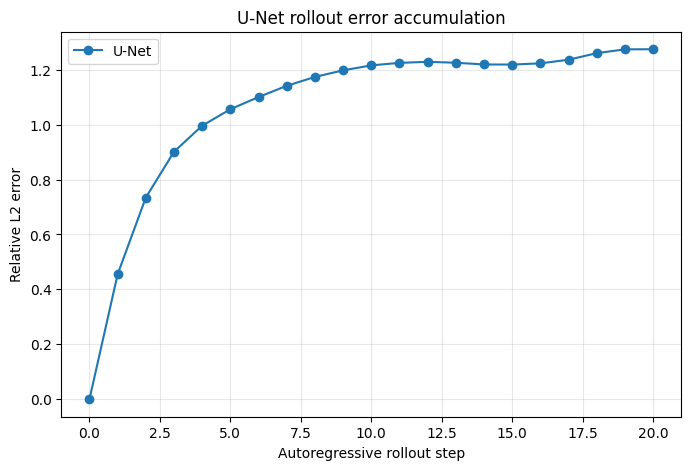

In [ ]:
mean_rollout_error = (
    unet_rollout_errors.mean(axis=0)
)

std_rollout_error = (
    unet_rollout_errors.std(axis=0)
)

steps = np.arange(
    len(mean_rollout_error)
)

plt.figure(figsize=(8, 5))

plt.plot(
    steps,
    mean_rollout_error,
    marker="o",
    label="U-Net",
)

# plt.fill_between(
#     steps,
#     mean_rollout_error
#     - std_rollout_error,
#     mean_rollout_error
#     + std_rollout_error,
#     alpha=0.2,
# )

plt.xlabel("Autoregressive rollout step")
plt.ylabel("Relative L2 error")

plt.title(
    "U-Net rollout error accumulation"
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [ ]:
def plot_rollout(
    true_trajectory,
    pred_trajectory,
    times=(0, 5, 10, 15, 20),
):

    n = len(times)

    fig, axes = plt.subplots(
        3,
        n,
        figsize=(3 * n, 8),
    )

    vmin = min(
        true_trajectory.min(),
        pred_trajectory.min(),
    )

    vmax = max(
        true_trajectory.max(),
        pred_trajectory.max(),
    )

    for j, t in enumerate(times):

        # -------------------------
        # Ground truth
        # -------------------------

        axes[0, j].imshow(
            true_trajectory[t],
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        axes[0, j].set_title(
            f"True t={t}"
        )

        # -------------------------
        # Prediction
        # -------------------------

        axes[1, j].imshow(
            pred_trajectory[t],
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        axes[1, j].set_title(
            f"Prediction t={t}"
        )

        # -------------------------
        # Error
        # -------------------------

        error = np.abs(
            pred_trajectory[t]
            - true_trajectory[t]
        )

        axes[2, j].imshow(
            error,
            origin="lower",
        )

        axes[2, j].set_title(
            f"|Error| t={t}"
        )

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    axes[0, 0].set_ylabel(
        "Ground truth"
    )

    axes[1, 0].set_ylabel(
        "U-Net"
    )

    axes[2, 0].set_ylabel(
        "Absolute error"
    )

    plt.tight_layout()
    plt.show()

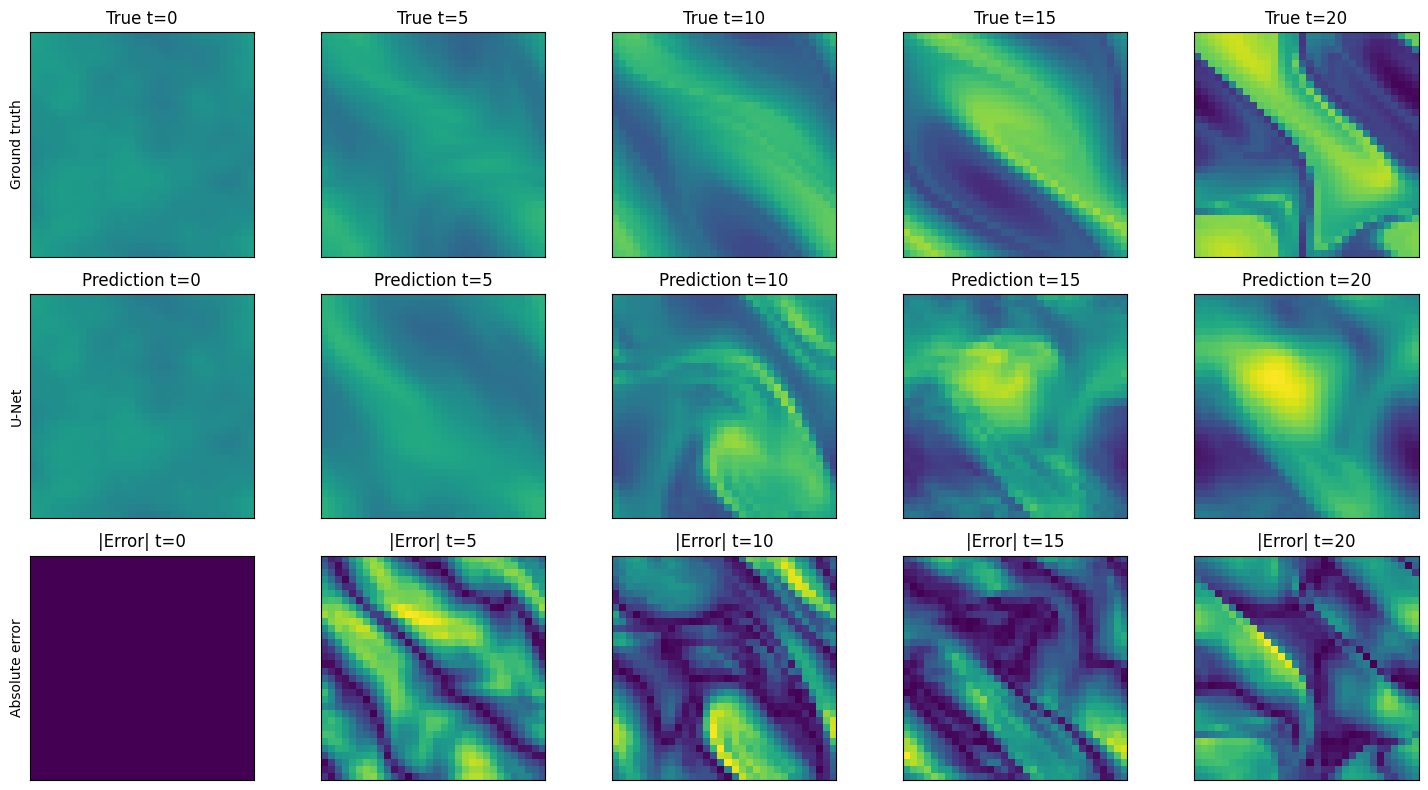

In [ ]:
plot_rollout(
    true_trajectory,
    pred_trajectory,
)

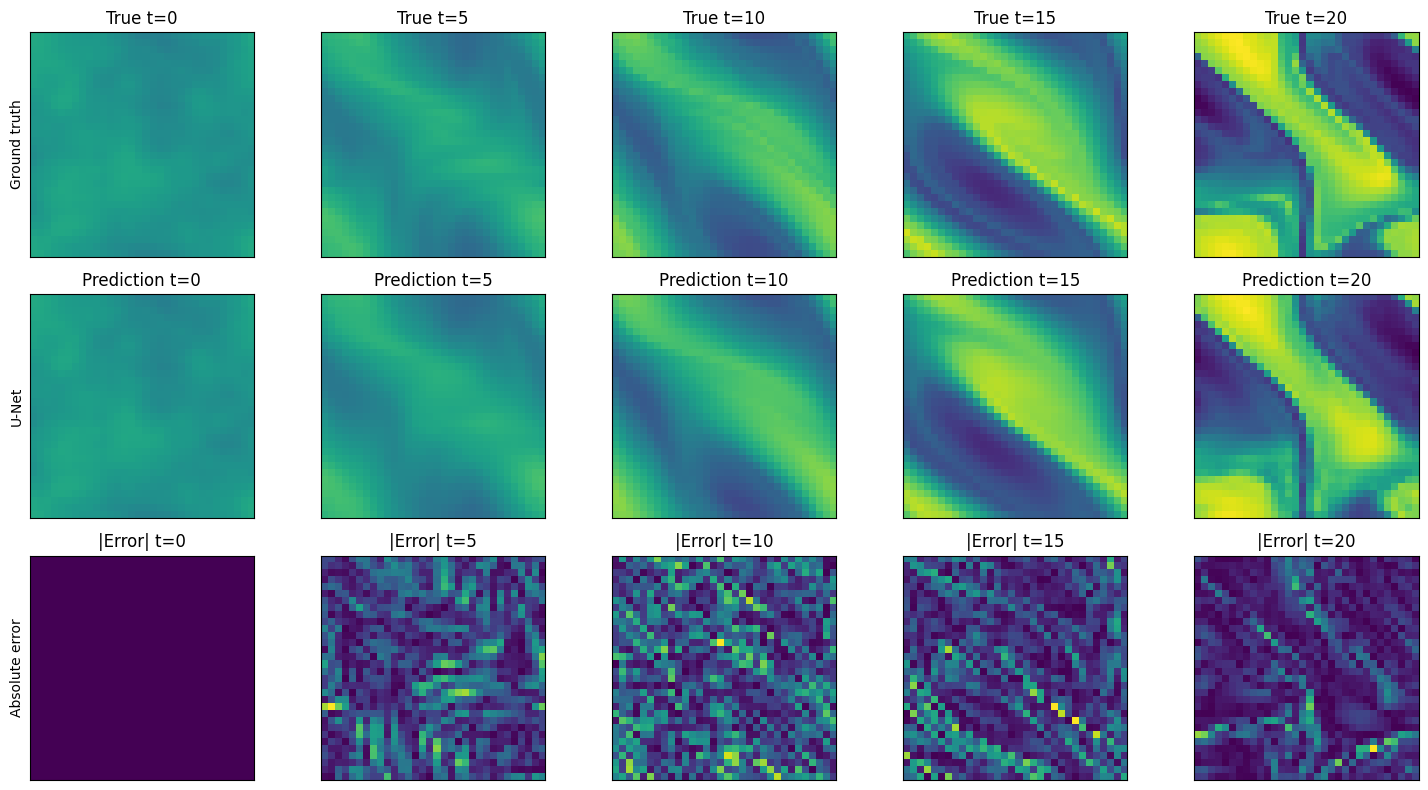

In [ ]:
plot_rollout(
    true_trajectory,
    teacher_forced_predictions,
)

## 7. A spatial Transformer

As an alternative to convolution, every grid point becomes a token. At the downsampled resolution, one field produces $32\times32=1024$ tokens. Global self-attention allows every location to interact directly with every other location.

A vorticity value alone does not identify a token's position, so we append periodic coordinates

$$[\sin(2\pi x),\cos(2\pi x),\sin(2\pi y),\cos(2\pi y)].$$

These features respect the topology of the periodic domain. Like the U-Net, the Transformer predicts a residual update.

> Global attention has quadratic cost in the number of tokens. Doubling resolution in both directions creates four times as many tokens and roughly sixteen times as many pairwise attention scores.

In [ ]:
def make_periodic_position_features(H, W):
    """
    Create periodic positional features for a H x W grid.

    Returns:
        pos: [H*W, 4]

    Features:
        sin(2*pi*x), cos(2*pi*x),
        sin(2*pi*y), cos(2*pi*y)
    """

    # Map indices to [0, 1); sine and cosine join both ends periodically.
    x = torch.arange(H, dtype=torch.float32) / H
    y = torch.arange(W, dtype=torch.float32) / W

    xx, yy = torch.meshgrid(
        x,
        y,
        indexing="ij",
    )

    pos = torch.stack(
        [
            torch.sin(2 * torch.pi * xx),
            torch.cos(2 * torch.pi * xx),
            torch.sin(2 * torch.pi * yy),
            torch.cos(2 * torch.pi * yy),
        ],
        dim=-1,
    )

    # [H, W, 4] -> [H*W, 4]
    pos = pos.reshape(H * W, 4)

    return pos

In [ ]:
class SpatialTransformer(nn.Module):

    def __init__(
        self,
        H,
        W,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dim_feedforward=256,
        dropout=0.0,
        residual_prediction=True,
    ):
        super().__init__()

        self.H = H
        self.W = W
        self.N = H * W

        self.residual_prediction = residual_prediction

        # -----------------------------------
        # Fixed periodic positional features
        # -----------------------------------

        pos = make_periodic_position_features(
            H,
            W,
        )

        self.register_buffer(
            "pos_features",
            pos,
        )

        # omega + 4 positional features
        self.input_projection = nn.Linear(
            5,
            d_model,
        )

        # -----------------------------------
        # Transformer encoder
        # -----------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        # -----------------------------------
        # Output: one scalar per grid point
        # -----------------------------------

        self.output_projection = nn.Linear(
            d_model,
            1,
        )


    def forward(self, x):
        """
        x:
            [B, 1, H, W]

        output:
            [B, 1, H, W]
        """

        B = x.shape[0]

        input_state = x

        # -----------------------------------
        # Convert grid to tokens
        # -----------------------------------

        # [B, 1, H, W]
        # ->
        # [B, H, W]
        x = x[:, 0]

        # ->
        # [B, N, 1]
        x = x.reshape(
            B,
            self.N,
            1,
        )

        # -----------------------------------
        # Add positional information
        # -----------------------------------

        # [N, 4]
        # ->
        # [B, N, 4]
        pos = self.pos_features.unsqueeze(0).expand(
            B,
            -1,
            -1,
        )

        # [B, N, 5]
        x = torch.cat(
            [x, pos],
            dim=-1,
        )

        # -----------------------------------
        # Token embedding
        # -----------------------------------

        # [B, N, 5]
        # ->
        # [B, N, d_model]
        x = self.input_projection(x)

        # -----------------------------------
        # Global self-attention
        # -----------------------------------

        x = self.transformer(x)

        x = self.norm(x)

        # -----------------------------------
        # Predict delta omega
        # -----------------------------------

        # [B, N, d_model]
        # ->
        # [B, N, 1]
        delta = self.output_projection(x)

        # ->
        # [B, 1, H, W]
        delta = delta.reshape(
            B,
            1,
            self.H,
            self.W,
        )

        if self.residual_prediction:
            return input_state + delta

        return delta

In [ ]:
# stride = 1 -> 64 x 64
# stride = 2 -> 32 x 32

H = 64 // SPATIAL_STRIDE
W = 64 // SPATIAL_STRIDE

transformer = SpatialTransformer(
    H=H,
    W=W,
    d_model=64,
    n_heads=4,
    n_layers=2,
    dim_feedforward=256,
    dropout=0.0,
    residual_prediction=True,
).to(device)

/tmp/ipykernel_1213/3077198302.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [ ]:
n_params = sum(
    p.numel()
    for p in transformer.parameters()
    if p.requires_grad
)

print(
    f"Transformer parameters: "
    f"{n_params:,}"
)

Transformer parameters: 100,545


### Training the Transformer

We reuse the same data, loss, optimizer family, and learning-rate schedule. Conclusions about architecture quality nevertheless require comparable training budgets and the same validation protocol.

In [ ]:
transformer_criterion = nn.MSELoss()

transformer_optimizer = torch.optim.AdamW(
    transformer.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

N_TRANSFORMER_EPOCHS = 30

transformer_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        transformer_optimizer,
        T_max=N_TRANSFORMER_EPOCHS,
    )
)

In [ ]:
transformer_train_losses = []
transformer_val_losses = []

best_transformer_val_loss = float("inf")
best_transformer_state = None

start_time = time.time()

for epoch in range(
    1,
    N_TRANSFORMER_EPOCHS + 1,
):

    train_loss = train_one_epoch(
        model=transformer,
        loader=train_loader,
        optimizer=transformer_optimizer,
        criterion=transformer_criterion,
        device=device,
    )

    val_loss = evaluate_loss(
        model=transformer,
        loader=val_loader,
        criterion=transformer_criterion,
        device=device,
    )

    transformer_train_losses.append(
        train_loss
    )

    transformer_val_losses.append(
        val_loss
    )

    if val_loss < best_transformer_val_loss:

        best_transformer_val_loss = val_loss

        best_transformer_state = copy.deepcopy(
            transformer.state_dict()
        )

    transformer_scheduler.step()

    print(
        f"Epoch "
        f"{epoch:3d}/"
        f"{N_TRANSFORMER_EPOCHS} | "
        f"Train: {train_loss:.6e} | "
        f"Val: {val_loss:.6e} | "
        f"LR: "
        f"{transformer_optimizer.param_groups[0]['lr']:.2e}"
    )


elapsed = time.time() - start_time

print()
print(
    f"Training time: "
    f"{elapsed / 60:.1f} minutes"
)

print(
    f"Best validation loss: "
    f"{best_transformer_val_loss:.6e}"
)

Epoch   1/30 | Train: 1.965435e-01 | Val: 1.516020e-01 | LR: 9.97e-04
Epoch   2/30 | Train: 1.284105e-01 | Val: 1.138511e-01 | LR: 9.89e-04
Epoch   3/30 | Train: 1.047337e-01 | Val: 9.905239e-02 | LR: 9.76e-04
Epoch   4/30 | Train: 9.124699e-02 | Val: 8.416104e-02 | LR: 9.57e-04
Epoch   5/30 | Train: 7.615828e-02 | Val: 6.765552e-02 | LR: 9.33e-04
Epoch   6/30 | Train: 5.898417e-02 | Val: 5.275226e-02 | LR: 9.05e-04
Epoch   7/30 | Train: 4.598776e-02 | Val: 4.291782e-02 | LR: 8.72e-04
Epoch   8/30 | Train: 3.945520e-02 | Val: 3.795741e-02 | LR: 8.35e-04
Epoch   9/30 | Train: 3.556166e-02 | Val: 3.499735e-02 | LR: 7.94e-04
Epoch  10/30 | Train: 3.285912e-02 | Val: 3.144825e-02 | LR: 7.50e-04
Epoch  11/30 | Train: 3.057290e-02 | Val: 2.890434e-02 | LR: 7.03e-04
Epoch  12/30 | Train: 2.837574e-02 | Val: 2.734597e-02 | LR: 6.55e-04
Epoch  13/30 | Train: 2.690021e-02 | Val: 2.660296e-02 | LR: 6.04e-04
Epoch  14/30 | Train: 2.538609e-02 | Val: 2.539028e-02 | LR: 5.52e-04
Epoch  15/30 | Train

In [ ]:
transformer.load_state_dict(
    best_transformer_state
)

transformer.eval()

print(
    "Best Transformer restored."
)

Best Transformer restored.


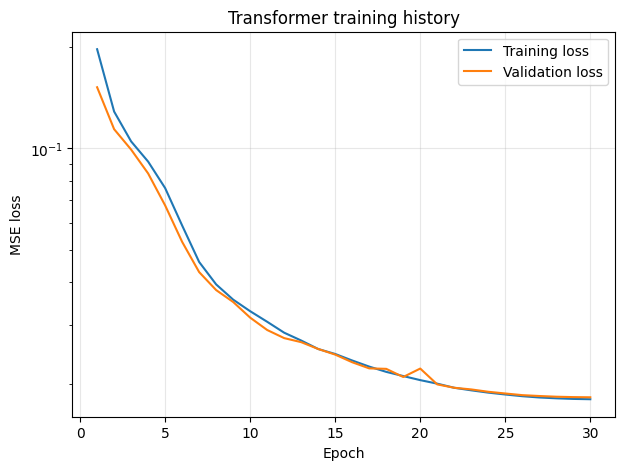

In [ ]:
epochs = np.arange(
    1,
    len(transformer_train_losses) + 1,
)

plt.figure(figsize=(7, 5))

plt.plot(
    epochs,
    transformer_train_losses,
    label="Training loss",
)

plt.plot(
    epochs,
    transformer_val_losses,
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Transformer training history")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Evaluating the Transformer

The Transformer uses the same one-step and rollout utilities as the U-Net. Shared evaluation code prevents preprocessing or metric differences from being mistaken for model differences.

In [ ]:
transformer_test_results = (
    evaluate_one_step(
        model=transformer,
        loader=test_loader,
        mean=omega_mean,
        std=omega_std,
        device=device,
    )
)

print(
    "Transformer one-step test results"
)

print(
    "---------------------------------"
)

for metric, value in (
    transformer_test_results.items()
):
    print(
        f"{metric:12s}: "
        f"{value:.6e}"
    )

Transformer one-step test results
---------------------------------
MSE         : 2.375252e-02
Relative L2 : 1.014821e-01


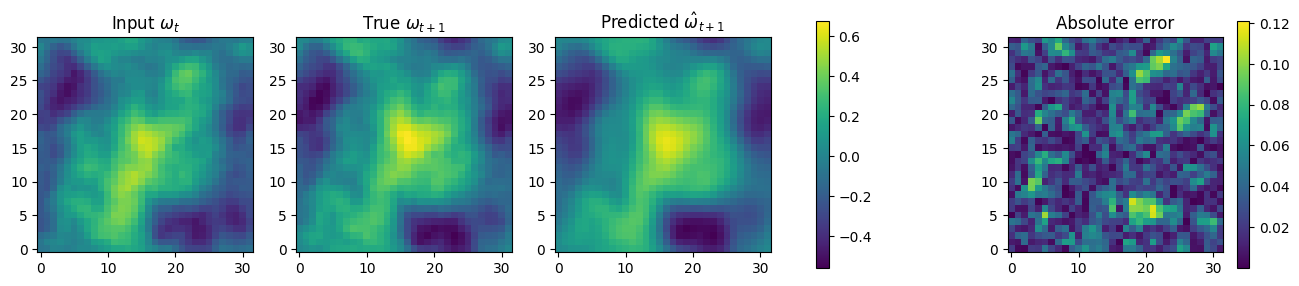

In [ ]:
plot_one_step_prediction(
    model=transformer,
    dataset=test_dataset,
    sample_idx=0,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

In [ ]:
(transformer_rollout_errors, transformer_teacher_forcing_errors) = (
    evaluate_rollouts(
        model=transformer,
        trajectory_indices=test_indices,
        initial_vorticity=initial_vorticity,
        vorticity=vorticity,
        spatial_stride=SPATIAL_STRIDE,
        mean=omega_mean,
        std=omega_std,
        device=device,
        n_steps=20,
    )
)

print("Autoregressive errors:", transformer_rollout_errors.shape)
print("Teacher-forced errors:", transformer_teacher_forcing_errors.shape)

Autoregressive errors: (200, 21)
Teacher-forced errors: (200, 21)


In [ ]:
trajectory_idx = test_indices[1]

true_trajectory = get_trajectory(
    trajectory_idx=trajectory_idx,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
)

pred_trajectory = rollout_model(
    model=transformer,
    initial_state=true_trajectory[0],
    n_steps=20,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

teacher_forced_predictions = rollout_model_teacher_forcing(
        model=transformer,
        true_trajectory=true_trajectory,
        mean=omega_mean,
        std=omega_std,
        device=device,
    )


print(
    "True trajectory:",
    true_trajectory.shape,
)

print(
    "Predicted trajectory:",
    pred_trajectory.shape,
)


print(
    "Predicted teacher forcing trajectory:",
    teacher_forced_predictions.shape,
)

True trajectory: (21, 32, 32)
Predicted trajectory: (21, 32, 32)
Predicted teacher forcing trajectory: (21, 32, 32)


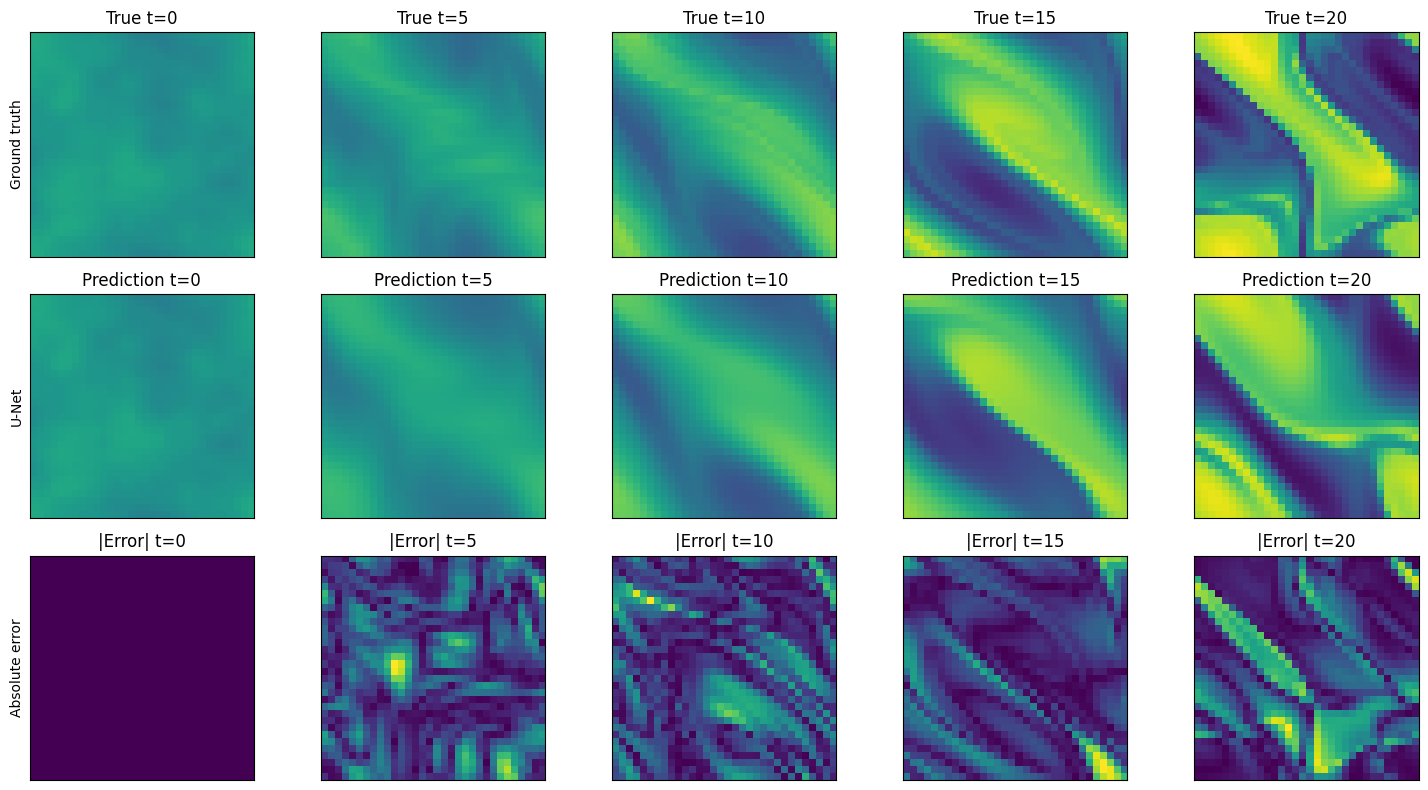

In [ ]:
plot_rollout(
    true_trajectory,
    pred_trajectory,
)

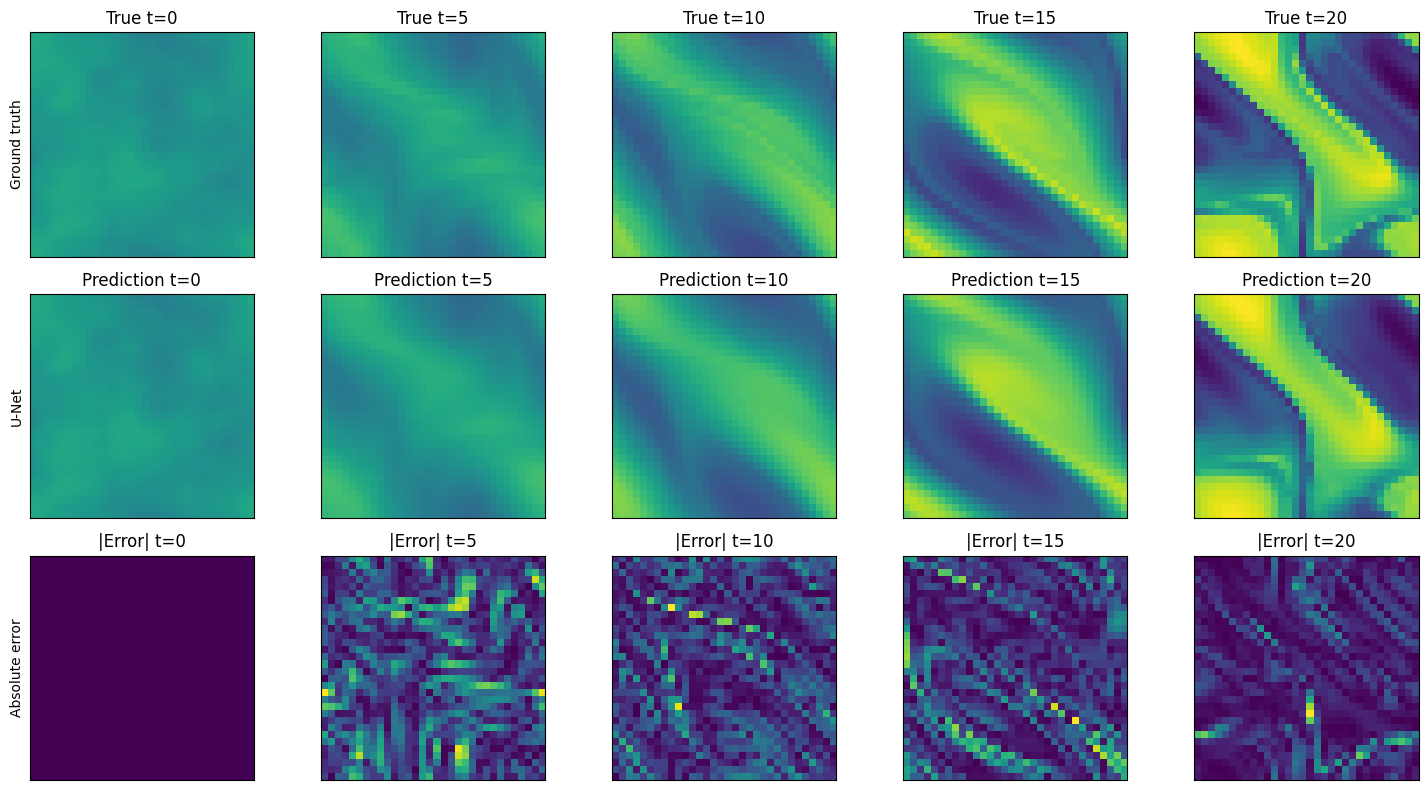

In [ ]:
plot_rollout(
    true_trajectory,
    teacher_forced_predictions,
)

## 8. Assignment: Faster attention with learned physics slices

The standard Transformer applies attention directly between all grid points. Our $32\times32$ field contains $N=1024$ point tokens, so every attention head constructs a $1024\times1024$ matrix. The cost grows quadratically with the number of grid points.

We adapt the main idea of [Transolver](https://arxiv.org/abs/2402.02366): first summarize the 1024 point tokens using only $M=64$ learned **physics-slice tokens**, apply attention between these summaries, and then send the resulting information back to all 1024 points.

> The model does **not** select 64 of the original grid points. Each slice token is a learned weighted average of all 1024 point tokens.

The complete information flow is

$$1024\text{ point tokens}\;\longrightarrow\;64\text{ learned summaries}\;\longrightarrow\;\text{attention}\;\longrightarrow\;1024\text{ updated point tokens}.$$

### Notation and tensor shapes

Let:

- $B$ be the batch size;
- $N=H\times W=1024$ be the number of grid points;
- $d=64$ be the token dimension;
- $h=4$ be the number of attention heads;
- $d_h=d/h=16$ be the feature dimension of one head; and
- $M=64$ be the number of learned slices.

The input to one slice-attention layer has shape

$$X\in\mathbb{R}^{B\times N\times d}.$$

### Step 1: split the point features into attention heads

First, apply a learned linear projection to the point features and reshape the result:

$$X\longrightarrow V\in\mathbb{R}^{B\times N\times h\times d_h}.$$

Thus, every grid point has a separate feature vector for every attention head.

### Step 2: give every point a soft membership in the slices

For each point and each head, project its $d_h$ features to $M$ slice scores. Apply softmax over the slice dimension:

$$W_{b,i,r,:}=\operatorname{softmax}(\operatorname{Project}(V_{b,i,r,:})),$$

where $i$ identifies a point and $r$ identifies an attention head. The resulting tensor has shape

$$W\in\mathbb{R}^{B\times N\times h\times M}.$$

Because softmax is applied across the $M$ slices, the memberships of one point sum to one:

$$\sum_{j=1}^{M}W_{b,i,r,j}=1.$$

For example, a point could belong 70% to slice 3, 20% to slice 17, and 10% to slice 42. These memberships are learned from the point features and can therefore change with the input field.

### Step 3: summarize the points into 64 slice tokens

For every head and slice, compute a weighted average of the point features:

$$Z_{b,r,j}=\frac{\sum_{i=1}^{N}W_{b,i,r,j}V_{b,i,r}}{\sum_{i=1}^{N}W_{b,i,r,j}+\varepsilon}.$$

The denominator is the total membership, or *mass*, of the slice. Dividing by it produces an average rather than a sum and avoids making heavily populated slices artificially large. A small $\varepsilon$ prevents division by zero.

The result has shape

$$Z\in\mathbb{R}^{B\times h\times M\times d_h}.$$

After concatenating the head dimensions, it becomes $[B,M,d]$. We have now compressed 1024 point tokens into 64 summary tokens. Spatially distant points may contribute to the same summary if the model gives them similar memberships.

### Step 4: apply ordinary attention to the 64 summaries

Apply standard multi-head self-attention to the slice tokens:

$$Q=ZW_Q,\qquad K=ZW_K,\qquad V_Z=ZW_V,$$

$$Z'=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_h}}\right)V_Z.$$

This attention matrix is only $64\times64$, rather than $1024\times1024$. The slice summaries exchange global information on behalf of the original grid points.

### Step 5: send the updated information back to all points

Reshape the updated slices back into heads and reuse the original memberships to reconstruct a feature for every point:

$$Y_{b,i,r}=\sum_{j=1}^{M}W_{b,i,r,j}Z'_{b,r,j}.$$

If a point belonged 70% to slice 3, 20% to slice 17, and 10% to slice 42, it receives the same mixture of the three updated slice representations. Concatenate the heads and apply an output projection to obtain

$$Y\in\mathbb{R}^{B\times N\times d}.$$

The layer therefore has the same input and output shape as standard self-attention and can replace it inside a Transformer block.

### Step 6: use the result in a Transformer block

As in the previous Transformer, we use layer normalization, residual connections, and a point-wise feed-forward network:

$$\widetilde X=X+\operatorname{SliceAttention}(\operatorname{LayerNorm}(X)),$$

$$X_{\mathrm{next}}=\widetilde X+\operatorname{MLP}(\operatorname{LayerNorm}(\widetilde X)).$$

After several blocks, a final linear layer converts every point feature into a scalar vorticity increment. The model predicts the next state residually:

$$\widehat{\omega}_{t+1}=\omega_t+\Delta\omega_\theta(\omega_t).$$

### Why this can be faster

Full point-wise attention costs approximately

$$\mathcal{O}(N^2d).$$

Slice attention requires point-to-slice aggregation, attention between slices, and slice-to-point reconstruction:

$$\mathcal{O}(NMd+M^2d).$$

For $N=1024$ and $M=64$, the notebook's simplified interaction count is reduced by about

$$\frac{N^2}{NM+M^2}\approx15.$$

This does not guarantee a $15\times$ wall-clock speedup: projections, aggregation, memory movement, and optimized GPU kernels also contribute to runtime. We therefore measure actual forward-pass time later.

### The accuracy–speed trade-off

The number of slices $M$ is the central hyperparameter:

- fewer slices give stronger compression and potentially higher speed, but may discard useful detail;
- more slices preserve more distinct physical states, but increase computation;
- setting $M=N$ largely removes the intended compression benefit.

<!-- > This is a teaching-oriented adaptation of Transolver, not an exact reproduction. It retains the paper's central slice–attend–deslice idea while using the periodic coordinates and one-step regression setup already developed in this notebook. -->
### Assignment

Your task is to implement exactly these three classes in the next two code cells:

1. `PhysicsSliceAttention` — point-to-slice assignment, slice attention, and slice-to-point reconstruction;
2. `PhysicsSliceBlock` — a pre-normalized residual attention/MLP block; and
3. `PhysicsSliceTransformer` — the complete one-step vorticity predictor.

Do not change their constructor arguments or the surrounding training and evaluation code. Use the equations and tensor shapes below as the specification, then complete the `__init__` and `forward` methods of each class. A correct implementation must preserve the requested shapes, remain differentiable, and run the later model-construction, training, timing, and rollout cells without modification.


In [ ]:
class PhysicsSliceAttention(nn.Module):
    """
    Compress N point tokens into M learned slice tokens, apply attention
    between slices, and map the result back to the original points.

    The soft assignments should be learned independently by each attention head.

    Args:
        d_model: Feature dimension of each point or slice token.
        n_heads: Number of attention heads. Must divide d_model evenly.
        n_slices: Number of learned slices used to summarize the points.
        dropout: Dropout probability for slice-level attention.
    """

    def __init__(
        self,
        d_model,
        n_heads=4,
        n_slices=64,
        dropout=0.0,
    ):
        super().__init__()

        # TODO: Define the dimensions, learned slice assignments, value
        # projection, slice-level self-attention, and output projection.
        # Use a separate slice projection for every attention head:
        #   slice_projection: [n_heads, head_dim, n_slices]
        #   slice_bias:       [n_heads, n_slices]
        self.head=d_model//n_heads
        self.n_heads = n_heads
        self.n_slices = n_slices
        self.slice_projection=nn.Parameter(torch.randn(n_heads,self.head,n_slices))
        self.slice_bias=nn.Parameter(torch.randn(n_heads,n_slices))
        self.slice_attention=nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, dropout=dropout, batch_first=True) #We declared here batch_first=True to make sure that the shape is matching the shape we are working with the whole notebook
        self.value_projection = nn.Linear(d_model, d_model)
        self.output_projection=nn.Linear(self.head*n_heads,d_model)
        #raise NotImplementedError("Complete PhysicsSliceAttention.__init__")


    def forward(self, x):
        # TODO: Implement the slice--attend--deslice operation described
        # above. Input and output shape: [B, N, d_model].
        B,N,d_model=x.shape
        V=self.value_projection(x) #x here is the embedded value already, B,N,d_model
        V=V.view(B,N,self.n_heads,self.head) #now we see it distributed in heads and the dimension per head B,N,n_heads, head_dim
        scores = torch.einsum("bnrd,rdm->bnrm", V, self.slice_projection)
        scores = scores +self.slice_bias
        W = F.softmax(scores, dim=-1)
        numerator = torch.einsum("bnrm,bnrd->brmd", W, V)
        mass = W.sum(dim=1)
        Z = numerator / (mass.unsqueeze(-1) + 1e-8)
        Z = Z.permute(0, 2, 1, 3).reshape(B, self.n_slices, d_model)
        Z_prime, _ = self.slice_attention(Z, Z, Z)
        Z_prime_heads = Z_prime.view(B, self.n_slices, self.n_heads, self.head).permute(0, 2, 1, 3)
        Y = torch.einsum("bnrm,brmd->bnrd", W, Z_prime_heads)
        Y = Y.reshape(B, N, d_model)
        output = self.output_projection(Y)
        return output

        #raise NotImplementedError("Complete PhysicsSliceAttention.forward")

In [ ]:
class PhysicsSliceBlock(nn.Module):
    """
    Pre-normalized slice-attention and feed-forward residual block.

    Args:
        d_model: Feature dimension of every token.
        n_heads: Number of heads in the slice-attention module.
        n_slices: Number of learned slice tokens.
        dim_feedforward: Hidden dimension of the point-wise MLP.
        dropout: Dropout probability used in attention and the MLP.
    """

    def __init__(
        self,
        d_model,
        n_heads,
        n_slices,
        dim_feedforward,
        dropout=0.0,
    ):
        super().__init__()

        # TODO: Follow the same pre-normalized structure as the standard
        # nn.TransformerEncoderLayer used in the transformer model in section 7.
        # Define two LayerNorm modules, one PhysicsSliceAttention module,
        # and an MLP with:
        # Linear(d_model, dim_feedforward) -> GELU -> Dropout ->
        # Linear(dim_feedforward, d_model) -> Dropout.
        # Only the standard self-attention is replaced by slice attention.
        self.norm1=nn.LayerNorm(d_model)
        self.norm2=nn.LayerNorm(d_model)
        self.physics_slice_attention=PhysicsSliceAttention(d_model,n_heads,n_slices,dropout)
        self.mlp=nn.Sequential(nn.Linear(d_model,dim_feedforward), nn.GELU(),nn.Dropout(dropout),nn.Linear(dim_feedforward,d_model),nn.Dropout(dropout))
        #raise NotImplementedError("Complete PhysicsSliceBlock.__init__")


    def forward(self, x):
        # TODO: Apply slice attention and the feed-forward network using the
        # pre-normalized residual structure described above.
        x=x+self.physics_slice_attention(self.norm1(x))
        x=x+self.mlp(self.norm2(x))
        return x
        #raise NotImplementedError("Complete PhysicsSliceBlock.forward")


class PhysicsSliceTransformer(nn.Module):
    """
    One-step vorticity predictor using learned slice attention.

    Args:
        H: Height of the input spatial grid.
        W: Width of the input spatial grid.
        d_model: Feature dimension of every token.
        n_heads: Number of attention heads in each slice block.
        n_layers: Number of consecutive PhysicsSliceBlock layers.
        n_slices: Number of learned slice tokens in each block.
        dim_feedforward: Hidden dimension of each block's MLP.
        dropout: Dropout probability used inside the blocks.
        residual_prediction: If True, add the predicted increment to the
            input field; otherwise return the increment alone.
    """

    def __init__(
        self,
        H,
        W,
        d_model=64,
        n_heads=4,
        n_layers=2,
        n_slices=64,
        dim_feedforward=128,
        dropout=0.0,
        residual_prediction=True,
    ):
        super().__init__()

        # TODO: Define the spatial metadata, periodic-position buffer, input
        # and output projections, stack of slice blocks, and final norm.
        self.H=H
        self.W=W
        self.N=H*W
        self.norm=nn.LayerNorm(d_model)
        self.blocks=nn.Sequential(*[PhysicsSliceBlock(d_model,n_heads,n_slices,dim_feedforward,dropout) for _ in range(n_layers)])

        self.residual_prediction=residual_prediction
        pos=make_periodic_position_features(H,W)
        self.register_buffer("pos",pos)
        self.input_projection=nn.Linear(5,d_model)
        self.output_projection=nn.Linear(d_model,1)
        #We recycled some code from past sections of SpatialTransformers

        #raise NotImplementedError("Complete PhysicsSliceTransformer.__init__")


    def forward(self, x):
        # TODO: Convert the field to position-aware tokens, process them with
        # the slice blocks, reconstruct the grid, and return either the
        # predicted increment or the residual next-state prediction.
        B = x.shape[0]
        input_state = x

        x = x[:, 0]
        x = x.reshape(B, self.N, 1)

        pos = self.pos.unsqueeze(0).expand(B, -1, -1)
        x = torch.cat([x, pos], dim=-1)

        x = self.input_projection(x)
        x = self.blocks(x)
        x = self.norm(x)

        delta = self.output_projection(x)
        delta = delta.reshape(B, 1, self.H, self.W)

        if self.residual_prediction:
            return input_state + delta
        return delta
        #ALL this code was recycled from the work done in section 7, names were adapted to our classes and functions but mainatined the original logic

        #raise NotImplementedError("Complete PhysicsSliceTransformer.forward")

In [ ]:
N_SLICES = 64

slice_transformer = PhysicsSliceTransformer(
    H=H,
    W=W,
    d_model=64,
    n_heads=4,
    n_layers=2,
    n_slices=N_SLICES,
    dim_feedforward=128,
    dropout=0.0,
    residual_prediction=True,
).to(device)

slice_n_params = sum(
    p.numel() for p in slice_transformer.parameters() if p.requires_grad
)

full_interactions = (H * W) ** 2
slice_interactions = (H * W) * N_SLICES + N_SLICES ** 2

print(f"Physics-slice Transformer parameters: {slice_n_params:,}")
print(f"Grid tokens: {H * W}; learned slices: {N_SLICES}")
print(
    "Interaction-count reduction: "
    f"{full_interactions / slice_interactions:.1f}x"
)

Physics-slice Transformer parameters: 92,865
Grid tokens: 1024; learned slices: 64
Interaction-count reduction: 15.1x


### Training

For a direct classroom comparison, this model uses the same optimizer settings and number of epochs as the full Transformer. The number of slices is the main efficiency–accuracy control: increasing it preserves more detail but increases both slicing and attention cost.

In [ ]:
slice_criterion = nn.MSELoss()
slice_optimizer = torch.optim.AdamW(
    slice_transformer.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

N_SLICE_EPOCHS = N_TRANSFORMER_EPOCHS

slice_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    slice_optimizer,
    T_max=N_SLICE_EPOCHS,
)

In [ ]:
slice_train_losses = []
slice_val_losses = []
best_slice_val_loss = float("inf")
best_slice_state = None

start_time = time.time()

for epoch in range(1, N_SLICE_EPOCHS + 1):
    train_loss = train_one_epoch(
        model=slice_transformer,
        loader=train_loader,
        optimizer=slice_optimizer,
        criterion=slice_criterion,
        device=device,
    )

    val_loss = evaluate_loss(
        model=slice_transformer,
        loader=val_loader,
        criterion=slice_criterion,
        device=device,
    )

    slice_train_losses.append(train_loss)
    slice_val_losses.append(val_loss)

    if val_loss < best_slice_val_loss:
        best_slice_val_loss = val_loss
        best_slice_state = copy.deepcopy(
            slice_transformer.state_dict()
        )

    slice_scheduler.step()

    print(
        f"Epoch {epoch:3d}/{N_SLICE_EPOCHS} | "
        f"Train: {train_loss:.6e} | "
        f"Val: {val_loss:.6e} | "
        f"LR: {slice_optimizer.param_groups[0]['lr']:.2e}"
    )

elapsed = time.time() - start_time

slice_transformer.load_state_dict(best_slice_state)
slice_transformer.eval()

print(f"Training time: {elapsed / 60:.1f} minutes")
print(f"Best validation loss: {best_slice_val_loss:.6e}")

Epoch   1/30 | Train: 1.810452e-01 | Val: 1.402374e-01 | LR: 9.97e-04
Epoch   2/30 | Train: 1.147154e-01 | Val: 9.920787e-02 | LR: 9.89e-04
Epoch   3/30 | Train: 9.030442e-02 | Val: 8.451192e-02 | LR: 9.76e-04
Epoch   4/30 | Train: 7.903772e-02 | Val: 7.915372e-02 | LR: 9.57e-04
Epoch   5/30 | Train: 7.233770e-02 | Val: 7.093817e-02 | LR: 9.33e-04
Epoch   6/30 | Train: 6.777327e-02 | Val: 6.732750e-02 | LR: 9.05e-04
Epoch   7/30 | Train: 6.391859e-02 | Val: 6.535476e-02 | LR: 8.72e-04
Epoch   8/30 | Train: 6.209686e-02 | Val: 6.131662e-02 | LR: 8.35e-04
Epoch   9/30 | Train: 5.913661e-02 | Val: 5.925794e-02 | LR: 7.94e-04
Epoch  10/30 | Train: 5.715325e-02 | Val: 5.823878e-02 | LR: 7.50e-04
Epoch  11/30 | Train: 5.543193e-02 | Val: 5.698483e-02 | LR: 7.03e-04
Epoch  12/30 | Train: 5.409767e-02 | Val: 5.475350e-02 | LR: 6.55e-04
Epoch  13/30 | Train: 5.301537e-02 | Val: 5.333222e-02 | LR: 6.04e-04
Epoch  14/30 | Train: 5.138927e-02 | Val: 5.235092e-02 | LR: 5.52e-04
Epoch  15/30 | Train

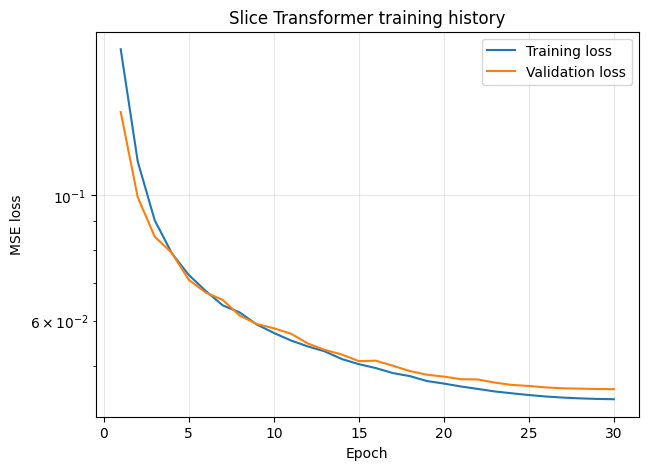

In [ ]:
epochs = np.arange(
    1,
    len(slice_train_losses) + 1,
)

plt.figure(figsize=(7, 5))

plt.plot(
    epochs,
    slice_train_losses,
    label="Training loss",
)

plt.plot(
    epochs,
    slice_val_losses,
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Slice Transformer training history")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Measuring actual speed

Asymptotic complexity is not the same as wall-clock speed. Small tensor operations, kernel-launch overhead, and optimized PyTorch attention kernels all matter. We therefore time complete forward passes after a warm-up. Run this benchmark on the same device and with the same batch for both models.

In [ ]:
@torch.no_grad()
def benchmark_forward_pass(
    model,
    inputs,
    n_warmup=10,
    n_repeats=50,
):
    """Return average forward-pass time in milliseconds."""
    model.eval()

    for _ in range(n_warmup):
        model(inputs)

    if inputs.is_cuda:
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(n_repeats):
        model(inputs)

    if inputs.is_cuda:
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    return 1000 * elapsed / n_repeats


timing_batch = x_batch.to(device).float()

full_transformer_ms = benchmark_forward_pass(
    transformer, timing_batch
)
slice_transformer_ms = benchmark_forward_pass(
    slice_transformer, timing_batch
)

print(f"Full Transformer:  {full_transformer_ms:.3f} ms/batch")
print(f"Slice Transformer: {slice_transformer_ms:.3f} ms/batch")
print(
    "Measured speedup:    "
    f"{full_transformer_ms / slice_transformer_ms:.2f}x"
)

Full Transformer:  87.963 ms/batch
Slice Transformer: 45.918 ms/batch
Measured speedup:    1.92x


### Accuracy and rollout evaluation

Speed is useful only if the compressed model remains accurate. We apply the same physical-unit metrics and autoregressive rollout test used above. Compare both one-step error and the shape of the rollout error curve.

In [ ]:
slice_test_results = evaluate_one_step(
    model=slice_transformer,
    loader=test_loader,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

print("Physics-slice Transformer one-step test results")
print("------------------------------------------------")
for metric, value in slice_test_results.items():
    print(f"{metric:12s}: {value:.6e}")

Physics-slice Transformer one-step test results
------------------------------------------------
MSE         : 5.810529e-02
Relative L2 : 1.655044e-01


In [ ]:
(
    slice_rollout_errors,
    slice_teacher_forcing_errors,
) = evaluate_rollouts(
    model=slice_transformer,
    trajectory_indices=test_indices,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
    mean=omega_mean,
    std=omega_std,
    device=device,
    n_steps=20,
)

print("Autoregressive errors:", slice_rollout_errors.shape)
print("Teacher-forced errors:", slice_teacher_forcing_errors.shape)

Autoregressive errors: (200, 21)
Teacher-forced errors: (200, 21)


In [ ]:
trajectory_idx = test_indices[1]

true_trajectory = get_trajectory(
    trajectory_idx=trajectory_idx,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
)

pred_trajectory = rollout_model(
    model=slice_transformer,
    initial_state=true_trajectory[0],
    n_steps=20,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

teacher_forced_predictions = rollout_model_teacher_forcing(
        model=slice_transformer,
        true_trajectory=true_trajectory,
        mean=omega_mean,
        std=omega_std,
        device=device,
    )


print(
    "True trajectory:",
    true_trajectory.shape,
)

print(
    "Predicted trajectory:",
    pred_trajectory.shape,
)


print(
    "Predicted teacher forcing trajectory:",
    teacher_forced_predictions.shape,
)

True trajectory: (21, 32, 32)
Predicted trajectory: (21, 32, 32)
Predicted teacher forcing trajectory: (21, 32, 32)


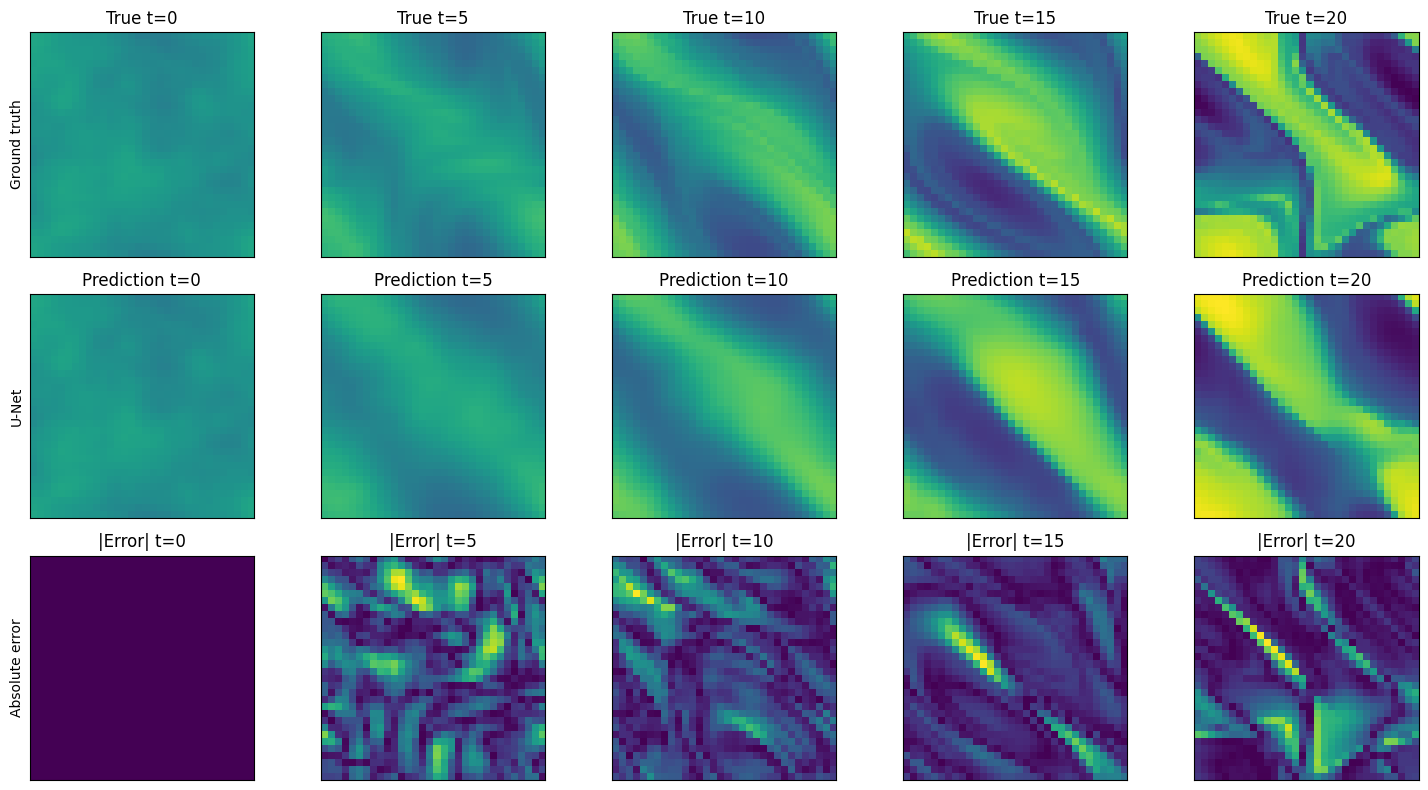

In [ ]:
plot_rollout(
    true_trajectory,
    pred_trajectory,
)

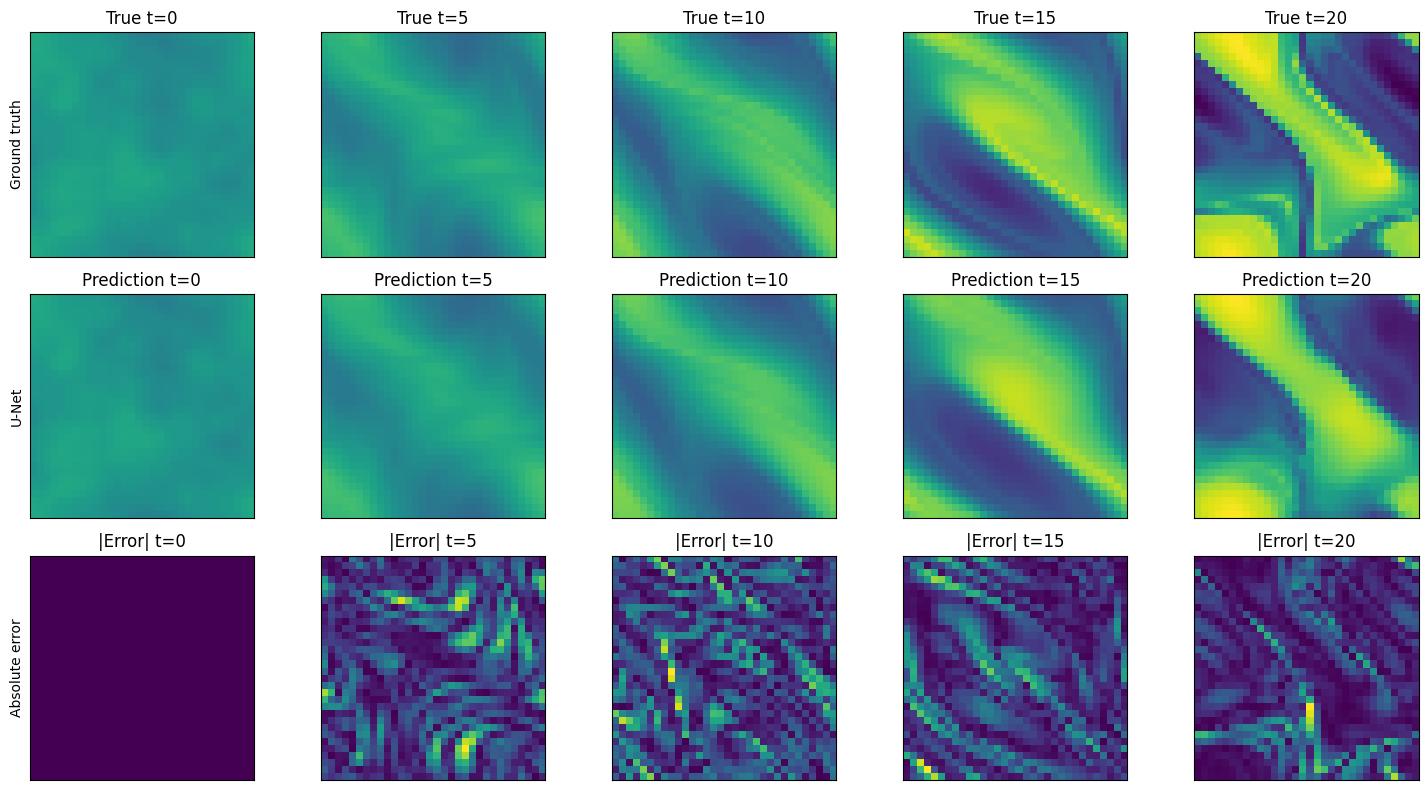

In [ ]:
plot_rollout(
    true_trajectory,
    teacher_forced_predictions,
)

## 9. Model comparison and discussion

The final cells compare one-step metrics and error growth over time.

In [ ]:
print(
    f"{'Model':15s} "
    f"{'MSE':>14s} "
    f"{'Relative L2':>14s}"
)

print("-" * 46)


print(
    f"{'U-Net':15s} "
    f"{unet_test_results['MSE']:14.6e} "
    f"{unet_test_results['Relative L2']:14.6e}"
)

print(
    f"{'Transformer':15s} "
    f"{transformer_test_results['MSE']:14.6e} "
    f"{transformer_test_results['Relative L2']:14.6e}"
)

print(
    f"{'Physics-slice':15s} "
    f"{slice_test_results['MSE']:14.6e} "
    f"{slice_test_results['Relative L2']:14.6e}"
)

Model                      MSE    Relative L2
----------------------------------------------
U-Net             2.643542e-02   1.354689e-01
Transformer       2.375252e-02   1.014821e-01
Physics-slice     5.810529e-02   1.655044e-01


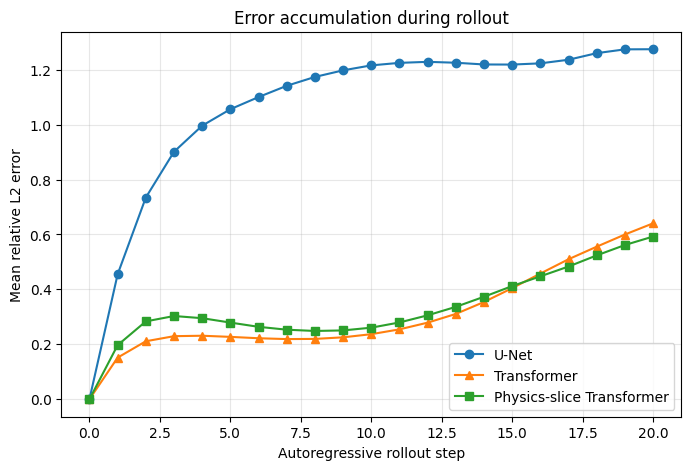

In [ ]:
unet_mean = (
    unet_rollout_errors.mean(
        axis=0
    )
)

transformer_mean = (
    transformer_rollout_errors.mean(
        axis=0
    )
)

slice_mean = (
    slice_rollout_errors.mean(
        axis=0
    )
)


steps = np.arange(
    len(transformer_mean)
)

plt.figure(figsize=(8, 5))


plt.plot(
    steps,
    unet_mean,
    marker="o",
    label="U-Net",
)

plt.plot(
    steps,
    transformer_mean,
    marker="^",
    label="Transformer",
)

plt.plot(
    steps,
    slice_mean,
    marker="s",
    label="Physics-slice Transformer",
)

plt.xlabel(
    "Autoregressive rollout step"
)

plt.ylabel(
    "Mean relative L2 error"
)

plt.title(
    "Error accumulation during rollout"
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

## 10. Assignment: Pushforward training for the Slice Transformer

In Section 8, you trained the physics-slice Transformer with ordinary one-step supervision. In this assignment, you will design and implement pushforward training for the same model. Pushforward training should expose the model to states produced by its own autoregressive predictions before applying the supervised loss.

### Tasks

- Implement a dataset class that supplies the trajectory information needed for pushforward training and supports the changing rollout horizon required by your scheduler.
- Implement the pushforward training procedure, including a one-epoch training function. Your implementation must perform the scheduled preliminary model steps without gradient tracking and apply the loss to the subsequent differentiable prediction.
- Design and implement a scheduler for the number of pushforward steps used during training. Explain your scheduling choice.
- Instantiate and train a new `PhysicsSliceTransformer` with the same architecture and model-size hyperparameters used in Section 8. Add any other code required for training, validation, checkpoint selection, and reproducibility.
- Plot the training and validation loss curves.
- Evaluate the trained model on the test set for both one-step prediction and autoregressive rollout, using the same metrics and evaluation conventions as in the previous sections.
- Compare the pushforward-trained model with the ordinarily trained physics-slice Transformer from Section 8. Discuss both one-step accuracy and how the relative L2 error develops over the rollout.

### Expected output

Your completed section should contain the dataset, scheduler, training and validation logic, a trained pushforward model, loss curves, one-step test metrics, rollout-error results, comparison plots, and a short interpretation of the results. The design of the dataset, scheduler, and training procedure is part of the assignment; no implementation template is provided.

First we need to think about a Pushforward scheduler. In class we briefly commented the idea of just do some epochs, then increase the pushforward, add some more and so on. We wanted to do a more adaptive aproach, we want the model to first be able to predict next t, when it gets good at one step, we can teach it to do 2 steps. We think the performance will be better than predefining the epochs ahead. We stated 4 maximum steps because learning more than 4 difficulty levels will most likely make the model learn how to predict purely noise. The implementation is quite straightforward, just following the logic of when do we move to the next difficulty level, but making sure we also add patience so that we do not mistakenly jump

In [ ]:
class PushforwardScheduler:
    def __init__(self, patience=3, threshold=1e-4, max_steps=4):
        self.patience = patience
        self.threshold = threshold
        self.max_steps = max_steps

        self.current_steps = 0
        self.best_loss = float("inf")
        self.bad_epochs = 0
    def step(self, val_loss):
        improvement = self.best_loss - val_loss

        if improvement > self.threshold:
            self.best_loss = val_loss
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1

            if self.bad_epochs >= self.patience and self.current_steps < self.max_steps:
                self.current_steps += 1
                self.bad_epochs = 0
                self.best_loss = float("inf")

        return self.current_steps

For the dataset we will recycle some more code from the assignment. In a nutshell, we had pairs created from each trajectory so we had the actual state and we want to find out the next state, the next step is the target. Now we want to make the model learn noise, so we need to be able to predict and follow multiple steps AND know they are from the same trajectory. We need to create a dataset that instead of getting pairs gets full trajectories

In [ ]:
class PushforwardDataset(Dataset):

    def __init__(
        self,
        initial_vorticity,
        vorticity,
        trajectory_indices,
        mean,
        std,
        spatial_stride=1,
    ):
        self.initial_vorticity = initial_vorticity
        self.vorticity = vorticity
        self.trajectory_indices = np.asarray(trajectory_indices)
        self.mean = mean
        self.std = std
        self.spatial_stride = spatial_stride

    def __len__(self):
        return len(self.trajectory_indices)
    def __getitem__(self, idx):

        trajectory_idx = self.trajectory_indices[idx]

        trajectory = get_trajectory(trajectory_idx=trajectory_idx, initial_vorticity=self.initial_vorticity,vorticity=self.vorticity,spatial_stride=self.spatial_stride,)


        trajectory = (trajectory - self.mean) / self.std

        trajectory = torch.from_numpy(trajectory)
        trajectory = trajectory.unsqueeze(1)

        return trajectory



We adapted the training function to make sure we are able to train n steps from the same trajectory. We need to do an iterative loop first to move forward n_steps, BUT we do not train over these steps, we just predict the next one. After n pushforward steps, we predict the next step and NOW this is the prediction we use for training, therefore learning the noise after n pushforward steps

In [ ]:
def train_one_epoch_pushforward(
    model,
    loader,
    optimizer,
    criterion,
    device,
    n_pushforward_steps,
):
    model.train()

    total_loss = 0.0
    n_samples = 0

    for trajectory in loader:
        trajectory = trajectory.to(device).float()

        B = trajectory.shape[0]
        n_states = trajectory.shape[1]

        max_start = n_states - n_pushforward_steps - 1  #we need to make sure t + n_pushforward_steps + 1 is not more than 20
        t = np.random.randint(0, max_start)

        x0 = trajectory[:, t]
        target = trajectory[:, t + n_pushforward_steps + 1]

        with torch.no_grad():
            current = x0
            for _ in range(n_pushforward_steps):
                current = model(current)        #we want to put the output of the model into the next input, just like rollout did before

        pred = model(current)

        loss = criterion(pred, target)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * B
        n_samples += B

    return total_loss / n_samples

The training logic is quite similar as before. We also added seed for reproducibility. What is new here is 2 main things: the training function itself is quite different, we move forward k steps without any gradient calculation and then one gradient step. This is way different than the 1 step 1 gradient training we did before. We also a tracker to make sure we record how hard does train get over time and when does it plateau, using the function defined before

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pushforward_train_dataset = PushforwardDataset(
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    trajectory_indices=train_indices,
    mean=omega_mean,
    std=omega_std,
    spatial_stride=SPATIAL_STRIDE,
)

pushforward_train_loader = DataLoader(
    pushforward_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

pf_transformer = PhysicsSliceTransformer(
    H=H, W=W, d_model=64, n_heads=4, n_layers=2,
    n_slices=N_SLICES, dim_feedforward=128, dropout=0.0,
    residual_prediction=True,
).to(device)

pf_criterion = nn.MSELoss()
pf_optimizer = torch.optim.AdamW(pf_transformer.parameters(), lr=1e-3, weight_decay=1e-4)
N_PF_EPOCHS = 30
pf_lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(pf_optimizer, T_max=N_PF_EPOCHS)

pf_scheduler = PushforwardScheduler(patience=3, threshold=1e-4, max_steps=4)

pf_train_losses = []
pf_val_losses = []
best_pf_val_loss = float("inf")
best_pf_state = None

for epoch in range(1, N_PF_EPOCHS + 1):
    current_k = pf_scheduler.current_steps

    train_loss = train_one_epoch_pushforward(
        model=pf_transformer,
        loader=pushforward_train_loader,
        optimizer=pf_optimizer,
        criterion=pf_criterion,
        device=device,
        n_pushforward_steps=current_k,
    )

    val_loss = evaluate_loss(
        model=pf_transformer,
        loader=val_loader,
        criterion=pf_criterion,
        device=device,
    )

    pf_train_losses.append(train_loss)
    pf_val_losses.append(val_loss)

    if val_loss < best_pf_val_loss:
        best_pf_val_loss = val_loss
        best_pf_state = copy.deepcopy(pf_transformer.state_dict())

    pf_lr_scheduler.step()
    new_k = pf_scheduler.step(val_loss)

    print(
        f"Epoch {epoch:3d}/{N_PF_EPOCHS} | K={current_k} | "
        f"Train: {train_loss:.6e} | Val: {val_loss:.6e}"
    )

pf_transformer.load_state_dict(best_pf_state)
pf_transformer.eval()

Epoch   1/30 | K=0 | Train: 4.201474e-01 | Val: 2.049034e-01
Epoch   2/30 | K=0 | Train: 3.791012e-02 | Val: 1.992960e-01
Epoch   3/30 | K=0 | Train: 1.606116e-01 | Val: 1.850502e-01
Epoch   4/30 | K=0 | Train: 3.546110e-01 | Val: 1.855836e-01
Epoch   5/30 | K=0 | Train: 1.984798e-01 | Val: 1.835532e-01
Epoch   6/30 | K=0 | Train: 9.803549e-02 | Val: 1.831936e-01
Epoch   7/30 | K=0 | Train: 9.809902e-02 | Val: 1.830339e-01
Epoch   8/30 | K=0 | Train: 1.641719e-01 | Val: 1.837503e-01
Epoch   9/30 | K=0 | Train: 1.944119e-01 | Val: 1.802497e-01
Epoch  10/30 | K=0 | Train: 5.184712e-02 | Val: 1.811362e-01
Epoch  11/30 | K=0 | Train: 1.811982e-01 | Val: 1.793974e-01
Epoch  12/30 | K=0 | Train: 1.786847e-02 | Val: 1.793902e-01
Epoch  13/30 | K=0 | Train: 5.394572e-02 | Val: 1.821987e-01
Epoch  14/30 | K=0 | Train: 5.264754e-02 | Val: 1.813672e-01
Epoch  15/30 | K=1 | Train: 2.927188e-01 | Val: 1.783421e-01
Epoch  16/30 | K=1 | Train: 2.651217e-01 | Val: 1.761913e-01
Epoch  17/30 | K=1 | Tra

PhysicsSliceTransformer(
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (blocks): Sequential(
    (0): PhysicsSliceBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (physics_slice_attention): PhysicsSliceAttention(
        (slice_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (value_projection): Linear(in_features=64, out_features=64, bias=True)
        (output_projection): Linear(in_features=64, out_features=64, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.0, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
        (4): Dropout(p=0.0, inplace=False)
      )
    )
    (1): PhysicsSliceBlock(
      (norm1): LayerNorm(

Now lets recycle a bunch of code for the evaluation part

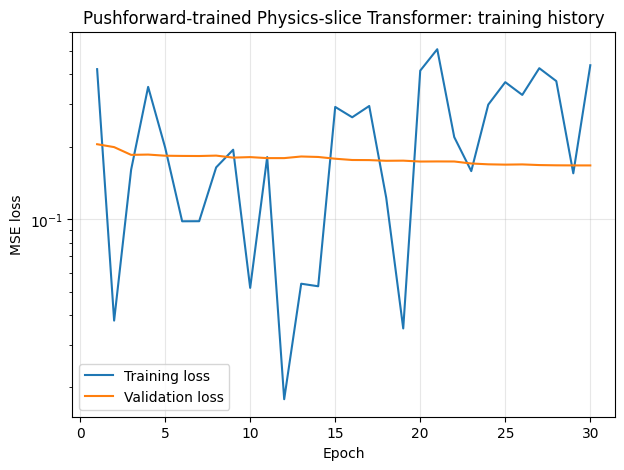

In [ ]:
epochs = np.arange(1, len(pf_train_losses) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs, pf_train_losses, label="Training loss")
plt.plot(epochs, pf_val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Pushforward-trained Physics-slice Transformer: training history")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
pf_test_results = evaluate_one_step(
    model=pf_transformer, loader=test_loader,
    mean=omega_mean, std=omega_std, device=device,
)
print("Pushforward-trained Physics-slice Transformer one-step test results")
for metric, value in pf_test_results.items():
    print(f"{metric:12s}: {value:.6e}")

pf_rollout_errors, pf_teacher_forcing_errors = evaluate_rollouts(
    model=pf_transformer, trajectory_indices=test_indices,
    initial_vorticity=initial_vorticity, vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE, mean=omega_mean, std=omega_std,
    device=device, n_steps=20,
)

Pushforward-trained Physics-slice Transformer one-step test results
MSE         : 2.129793e-01
Relative L2 : 2.825346e-01


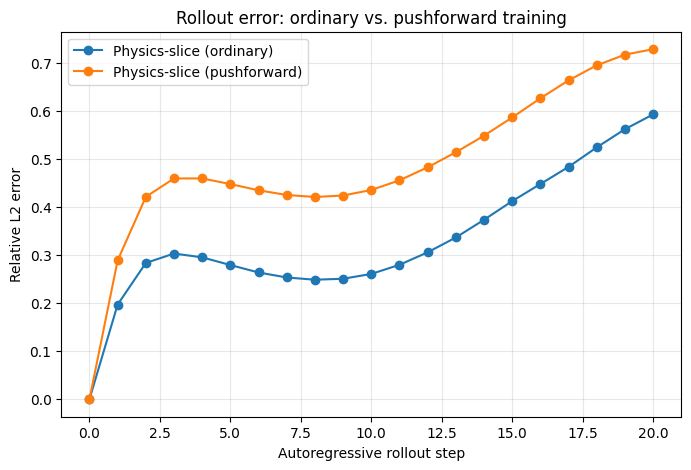

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(21), slice_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (ordinary)")
plt.plot(np.arange(21), pf_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (pushforward)")
plt.xlabel("Autoregressive rollout step")
plt.ylabel("Relative L2 error")
plt.title("Rollout error: ordinary vs. pushforward training")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

NEW TRY:
Results are worse so maybe we should retry using a more deterministic get push forward method in which we deterministically select the number of epochs needed to update the pushforward steps. The rest is all the same. We also added in both implementations gradient clipping to try to stabalize the training

In [ ]:
def get_pushforward_steps_simple(epoch, epochs_per_increase=6, max_steps=4):

    return min(max_steps, (epoch - 1) // epochs_per_increase)


def train_one_epoch_pushforward_clipped(
    model,
    loader,
    optimizer,
    criterion,
    device,
    n_pushforward_steps,
    max_grad_norm=1.0,
):
    model.train()
    total_loss = 0.0
    n_samples = 0

    for trajectory in loader:
        trajectory = trajectory.to(device).float()
        B = trajectory.shape[0]
        n_states = trajectory.shape[1]

        max_start = n_states - n_pushforward_steps - 1
        t = np.random.randint(0, max_start)

        x0 = trajectory[:, t]
        target = trajectory[:, t + n_pushforward_steps + 1]

        with torch.no_grad():
            current = x0
            for _ in range(n_pushforward_steps):
                current = model(current)

        pred = model(current)
        loss = criterion(pred, target)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        total_loss += loss.item() * B
        n_samples += B

    return total_loss / n_samples

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pf2_transformer = PhysicsSliceTransformer(
    H=H, W=W, d_model=64, n_heads=4, n_layers=2,
    n_slices=N_SLICES, dim_feedforward=128, dropout=0.0,
    residual_prediction=True,
).to(device)

pf2_criterion = nn.MSELoss()
pf2_optimizer = torch.optim.AdamW(pf2_transformer.parameters(), lr=1e-3, weight_decay=1e-4)
N_PF2_EPOCHS = 30
pf2_lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(pf2_optimizer, T_max=N_PF2_EPOCHS)

EPOCHS_PER_INCREASE = 6
MAX_PF_STEPS = 4

pf2_train_losses = []
pf2_val_losses = []
best_pf2_val_loss = float("inf")
best_pf2_state = None

for epoch in range(1, N_PF2_EPOCHS + 1):
    current_k = get_pushforward_steps_simple(epoch, EPOCHS_PER_INCREASE, MAX_PF_STEPS)

    train_loss = train_one_epoch_pushforward_clipped(
        model=pf2_transformer,
        loader=pushforward_train_loader,
        optimizer=pf2_optimizer,
        criterion=pf2_criterion,
        device=device,
        n_pushforward_steps=current_k,
    )

    val_loss = evaluate_loss(
        model=pf2_transformer, loader=val_loader,
        criterion=pf2_criterion, device=device,
    )

    pf2_train_losses.append(train_loss)
    pf2_val_losses.append(val_loss)

    if val_loss < best_pf2_val_loss:
        best_pf2_val_loss = val_loss
        best_pf2_state = copy.deepcopy(pf2_transformer.state_dict())

    pf2_lr_scheduler.step()

    print(f"Epoch {epoch:3d}/{N_PF2_EPOCHS} | K={current_k} | "
          f"Train: {train_loss:.6e} | Val: {val_loss:.6e}")

pf2_transformer.load_state_dict(best_pf2_state)
pf2_transformer.eval()

Epoch   1/30 | K=0 | Train: 4.201474e-01 | Val: 2.049034e-01
Epoch   2/30 | K=0 | Train: 3.791012e-02 | Val: 1.992960e-01
Epoch   3/30 | K=0 | Train: 1.606116e-01 | Val: 1.850502e-01
Epoch   4/30 | K=0 | Train: 3.546110e-01 | Val: 1.855836e-01
Epoch   5/30 | K=0 | Train: 1.984798e-01 | Val: 1.835532e-01
Epoch   6/30 | K=0 | Train: 9.803549e-02 | Val: 1.831936e-01
Epoch   7/30 | K=1 | Train: 2.094723e-01 | Val: 1.819076e-01
Epoch   8/30 | K=1 | Train: 3.829204e-01 | Val: 1.798471e-01
Epoch   9/30 | K=1 | Train: 4.590431e-01 | Val: 1.811289e-01
Epoch  10/30 | K=1 | Train: 1.644643e-01 | Val: 1.787759e-01
Epoch  11/30 | K=1 | Train: 3.604339e-01 | Val: 1.832903e-01
Epoch  12/30 | K=1 | Train: 6.905696e-02 | Val: 1.787568e-01
Epoch  13/30 | K=2 | Train: 2.539533e-01 | Val: 1.774802e-01
Epoch  14/30 | K=2 | Train: 2.425595e-01 | Val: 1.768777e-01
Epoch  15/30 | K=2 | Train: 4.730311e-01 | Val: 1.744594e-01
Epoch  16/30 | K=2 | Train: 4.328570e-01 | Val: 1.750572e-01
Epoch  17/30 | K=2 | Tra

PhysicsSliceTransformer(
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (blocks): Sequential(
    (0): PhysicsSliceBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (physics_slice_attention): PhysicsSliceAttention(
        (slice_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (value_projection): Linear(in_features=64, out_features=64, bias=True)
        (output_projection): Linear(in_features=64, out_features=64, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.0, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
        (4): Dropout(p=0.0, inplace=False)
      )
    )
    (1): PhysicsSliceBlock(
      (norm1): LayerNorm(

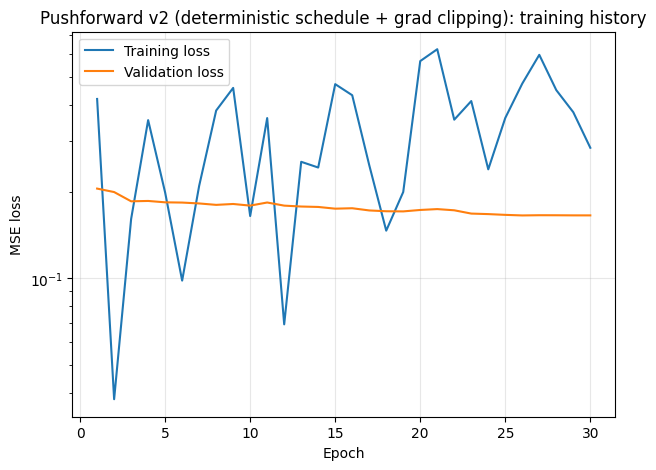

In [ ]:
epochs = np.arange(1, len(pf2_train_losses) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, pf2_train_losses, label="Training loss")
plt.plot(epochs, pf2_val_losses, label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("Pushforward v2 (deterministic schedule + grad clipping): training history")
plt.yscale("log"); plt.grid(alpha=0.3); plt.legend()
plt.show()

pf2_rollout_errors, _ = evaluate_rollouts(
    model=pf2_transformer, trajectory_indices=test_indices,
    initial_vorticity=initial_vorticity, vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE, mean=omega_mean, std=omega_std,
    device=device, n_steps=20,
)

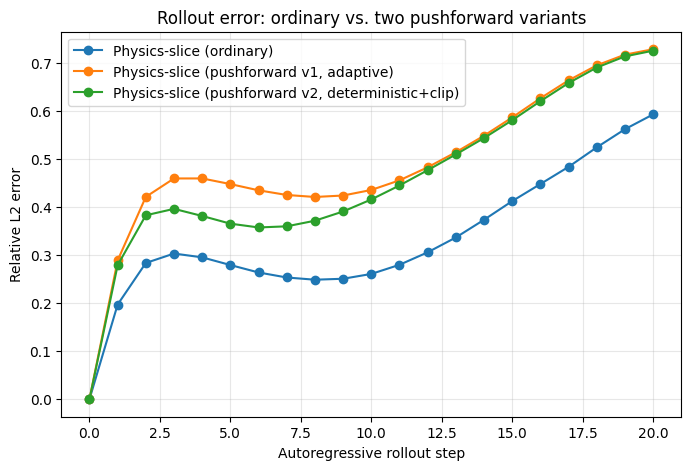

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(np.arange(21), slice_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (ordinary)")
plt.plot(np.arange(21), pf_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (pushforward v1, adaptive)")
plt.plot(np.arange(21), pf2_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (pushforward v2, deterministic+clip)")

plt.xlabel("Autoregressive rollout step")
plt.ylabel("Relative L2 error")
plt.title("Rollout error: ordinary vs. two pushforward variants")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

As we can see, there was some improvement regarding the first version, but both methods are worse than the ordinary model, which is somehow surprising. Our theory is the following: now that we are using batches of trajectories instead of pairs, we are meaningfully reducing the amount of training data we have available. A lot of steps do not produce gradients so we are not training on them, we are loosing information in those steps (eventhough this is exactly what we are meant to do). We can easily check whether thats true by allowing the model to use multiple steps from the same trajectory. We need o be careful about the output and make sure we are not overtraining our model.

In [ ]:
def train_one_epoch_pushforward_repeated(
    model,
    loader,
    optimizer,
    criterion,
    device,
    n_pushforward_steps,
    n_repeats_per_batch=20,
    max_grad_norm=1.0,
):
    model.train()
    total_loss = 0.0
    n_samples = 0

    for trajectory in loader:
        trajectory = trajectory.to(device).float()
        B = trajectory.shape[0]
        n_states = trajectory.shape[1]
        max_start = n_states - n_pushforward_steps - 1

        for _ in range(n_repeats_per_batch):
            t = np.random.randint(0, max_start)

            x0 = trajectory[:, t]
            target = trajectory[:, t + n_pushforward_steps + 1]

            with torch.no_grad():
                current = x0
                for _ in range(n_pushforward_steps):
                    current = model(current)

            pred = model(current)
            loss = criterion(pred, target)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()

            total_loss += loss.item() * B
            n_samples += B

    return total_loss / n_samples

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pf3_transformer = PhysicsSliceTransformer(
    H=H, W=W, d_model=64, n_heads=4, n_layers=2,
    n_slices=N_SLICES, dim_feedforward=128, dropout=0.0,
    residual_prediction=True,
).to(device)

pf3_criterion = nn.MSELoss()
pf3_optimizer = torch.optim.AdamW(pf3_transformer.parameters(), lr=1e-3, weight_decay=1e-4)
N_PF3_EPOCHS = 30
pf3_lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(pf3_optimizer, T_max=N_PF3_EPOCHS)

EPOCHS_PER_INCREASE = 6
MAX_PF_STEPS = 4
N_REPEATS_PER_BATCH = 20

pf3_train_losses = []
pf3_val_losses = []
best_pf3_val_loss = float("inf")
best_pf3_state = None

start_time = time.time()

for epoch in range(1, N_PF3_EPOCHS + 1):
    current_k = get_pushforward_steps_simple(epoch, EPOCHS_PER_INCREASE, MAX_PF_STEPS)

    train_loss = train_one_epoch_pushforward_repeated(
        model=pf3_transformer,
        loader=pushforward_train_loader,
        optimizer=pf3_optimizer,
        criterion=pf3_criterion,
        device=device,
        n_pushforward_steps=current_k,
        n_repeats_per_batch=N_REPEATS_PER_BATCH,
    )

    val_loss = evaluate_loss(
        model=pf3_transformer, loader=val_loader,
        criterion=pf3_criterion, device=device,
    )

    pf3_train_losses.append(train_loss)
    pf3_val_losses.append(val_loss)

    if val_loss < best_pf3_val_loss:
        best_pf3_val_loss = val_loss
        best_pf3_state = copy.deepcopy(pf3_transformer.state_dict())

    pf3_lr_scheduler.step()

    print(f"Epoch {epoch:3d}/{N_PF3_EPOCHS} | K={current_k} | "
          f"Train: {train_loss:.6e} | Val: {val_loss:.6e}")

elapsed = time.time() - start_time

pf3_transformer.load_state_dict(best_pf3_state)
pf3_transformer.eval()

print(f"\nTraining time: {elapsed / 60:.1f} minutes")
print(f"Best validation loss: {best_pf3_val_loss:.6e}")

Epoch   1/30 | K=0 | Train: 1.556462e-01 | Val: 1.709145e-01
Epoch   2/30 | K=0 | Train: 1.792683e-01 | Val: 1.294074e-01
Epoch   3/30 | K=0 | Train: 1.246661e-01 | Val: 1.241667e-01
Epoch   4/30 | K=0 | Train: 1.077705e-01 | Val: 1.199483e-01
Epoch   5/30 | K=0 | Train: 1.046570e-01 | Val: 1.064832e-01
Epoch   6/30 | K=0 | Train: 8.084562e-02 | Val: 1.188806e-01
Epoch   7/30 | K=1 | Train: 1.689561e-01 | Val: 1.224247e-01
Epoch   8/30 | K=1 | Train: 1.368805e-01 | Val: 1.015129e-01
Epoch   9/30 | K=1 | Train: 1.178833e-01 | Val: 1.251662e-01
Epoch  10/30 | K=1 | Train: 1.297591e-01 | Val: 1.053242e-01
Epoch  11/30 | K=1 | Train: 1.212707e-01 | Val: 9.799380e-02
Epoch  12/30 | K=1 | Train: 1.154605e-01 | Val: 9.598852e-02
Epoch  13/30 | K=2 | Train: 1.472131e-01 | Val: 1.075068e-01
Epoch  14/30 | K=2 | Train: 1.876090e-01 | Val: 1.558637e-01
Epoch  15/30 | K=2 | Train: 1.637177e-01 | Val: 9.540372e-02
Epoch  16/30 | K=2 | Train: 1.275336e-01 | Val: 9.636881e-02
Epoch  17/30 | K=2 | Tra

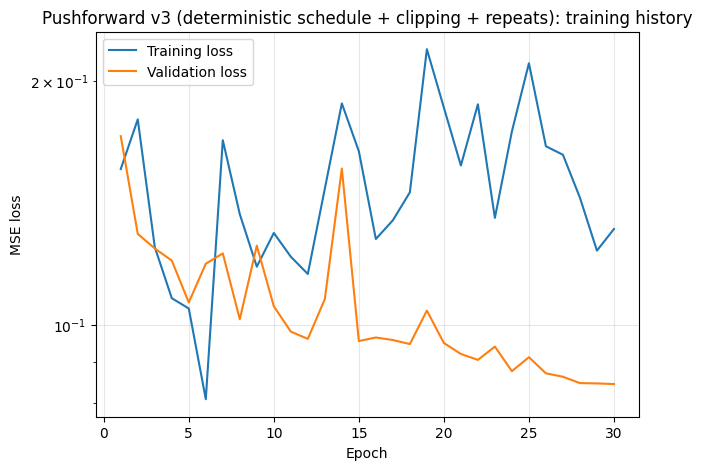

In [ ]:
epochs = np.arange(1, len(pf3_train_losses) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, pf3_train_losses, label="Training loss")
plt.plot(epochs, pf3_val_losses, label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("Pushforward v3 (deterministic schedule + clipping + repeats): training history")
plt.yscale("log"); plt.grid(alpha=0.3); plt.legend()
plt.show()

In [ ]:
pf3_rollout_errors, _ = evaluate_rollouts(
    model=pf3_transformer, trajectory_indices=test_indices,
    initial_vorticity=initial_vorticity, vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE, mean=omega_mean, std=omega_std,
    device=device, n_steps=20,
)

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(21), slice_rollout_errors.mean(axis=0), marker="o", label="Physics-slice (ordinary)")
plt.plot(np.arange(21), pf_rollout_errors.mean(axis=0), marker="o", label="Pushforward v1 (adaptive)")
plt.plot(np.arange(21), pf2_rollout_errors.mean(axis=0), marker="o", label="Pushforward v2 (deterministic+clip)")
plt.plot(np.arange(21), pf3_rollout_errors.mean(axis=0), marker="o", label="Pushforward v3 (+repeats)")
plt.xlabel("Autoregressive rollout step")
plt.ylabel("Relative L2 error")
plt.title("Rollout error: ordinary vs. three pushforward variants")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Now we created a parameter with n repeats per batch that allows the training to be done muliple times to the same batch. First thing we notice is that it takes way longer as it has nearly the same number of updates as the original code (140 updates) but of course now we predict a lot of steps without tracking the gradient. We can see that this was indeed the main problem we had before and the reason why we were not able to reach a stable training. Now we can see how the validation loss decreases very steadily, but the training loss is not stable at all.

We can see that in the first epochs its performance is better than the other methods but slightly worse than the ordinary method, but what is really curious and also makes sense when we dive deep into it is that after 15 rollouts we can see it is better than the ordinary method. Why would this happen? Our theory is that we now have a method with roughly the same amount of updates but it is made specifically to make sure we learn how to handle noise. We know the error is accumulative, therefore the ordinary model assumes no previous error at all and thats why in the first steps it predicts better, because the model was trained to not assume noise. Our current model does assume noise, therefore the result is quite clear: the first steps it predicts slighlty worse because it "assumes" noise is in the data, but it is minimum in the first steps. After 15 steps error accumulate an it gets higher. Here is the breaking point where our model acts more robust and is now capable of learning how to handle cumulative error over steps. We can see at step 20 the difference is significant between both methods, so our new pushforward method provides an alternative simulation that works better for long term runs. The other 2 versions stay obsolete as they did not squeeze as much as they could the training data, we can easily notice this in the training time and the loss curves

In [ ]:
pf3_test_results = evaluate_one_step(
    model=pf3_transformer, loader=test_loader,
    mean=omega_mean, std=omega_std, device=device,
)

print("Pushforward-trained Physics-slice Transformer (v3) one-step test results")
for metric, value in pf3_test_results.items():
    print(f"{metric:12s}: {value:.6e}")

print()
print(f"{'Model':30s} {'MSE':>14s} {'Relative L2':>14s}")
print("-" * 60)
print(f"{'Physics-slice (no pushforward)':30s} {slice_test_results['MSE']:14.6e} {slice_test_results['Relative L2']:14.6e}")
print(f"{'Physics-slice (pushforward)':30s} {pf3_test_results['MSE']:14.6e} {pf3_test_results['Relative L2']:14.6e}")

In [ ]:
trajectory_idx = test_indices[1]

true_trajectory_pf3 = get_trajectory(
    trajectory_idx=trajectory_idx,
    initial_vorticity=initial_vorticity,
    vorticity=vorticity,
    spatial_stride=SPATIAL_STRIDE,
)

pred_trajectory_pf3 = rollout_model(
    model=pf3_transformer,
    initial_state=true_trajectory_pf3[0],
    n_steps=20,
    mean=omega_mean,
    std=omega_std,
    device=device,
)

plot_rollout(
    true_trajectory_pf3,
    pred_trajectory_pf3,
    times=(0, 5, 10, 15, 20),
)